# Analisis Data Eksploratif: Air Quality (UCI)


**Peta navigasi**

| Bagian | Isi | Sel |
|---|---|---|
| A. Data Understanding | Deskripsi dataset, kamus variabel, pemeriksaan awal | 1–9 |
| B. Data Preparation | Missing values, outlier (IQR), transformasi | 10–17 |
| C. Univariat | Numerik dan kategorik | 18–19 |
| D. Bivariat | Numerik–numerik, kategorik–kategorik, numerik–kategorik | 20–23 |
| E. Multivariat | PCA dan K-Means | 24–28 |
| Penutup | Penyimpanan hasil dan ringkasan | 29 |



## A.1 Deskripsi Dataset

**1. Nama dan sumber.** *Air Quality Data Set*, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/360/air+quality). Dataset ini berasal dari S. De Vito dkk. (2008), *On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario*, Sensors and Actuators B: Chemical. Tanggal akses ditampilkan pada Sel 1.

**Alasan pemilihan.** Saya memilih dataset ini karena menarik perhatian saya. Isu kualitas udara terasa dekat dengan kehidupan sehari-hari, dan saya penasaran bagaimana angka-angka dari sensor yang terlihat teknis bisa menceritakan pola yang sebenarnya kita alami, misalnya kapan udara paling tercemar dalam sehari. Selain itu, dataset ini cukup lengkap sebagai bahan belajar. Datanya dicatat per jam selama lebih dari setahun dengan lebih dari 9.000 observasi, sehingga polanya cukup kaya untuk dianalisis. Datanya juga tidak "terlalu bersih": ada nilai hilang yang ditandai dengan kode `-200`, ada lonjakan polutan yang ekstrem, dan banyak variabel yang saling berkaitan. Kondisi seperti ini justru mirip dengan data di dunia nyata, sehingga setiap teknik yang diminta tugas (penanganan missing values, deteksi outlier dengan IQR, korelasi, uji hipotesis, PCA, dan K-Means) dapat dipraktikkan secara bermakna, bukan sekadar mengikuti langkah-langkah di buku.
**2. Dimensi.** 9.357 baris (observasi per jam) dan 15 kolom (13 variabel pengukuran ditambah `Date` dan `Time`). Setelah baris kosong di akhir berkas dibuang, jumlah baris dikonfirmasi oleh Sel 3.

**3. Konteks.** Data dikumpulkan oleh stasiun pemantau kualitas udara di tingkat jalan (*road level*) pada area perkotaan yang cukup tercemar di Italia, dari Maret 2004 sampai April 2005. Lima sensor kimia berbasis oksida logam (PT08.S1–S5) merekam respons gas secara kontinu, sedangkan analyzer referensi bersertifikat (kolom berakhiran `(GT)`, *ground truth*) merekam konsentrasi CO, NMHC, benzena, NOx, dan NO2 sebagai rata-rata per jam. Data dipakai untuk mengkalibrasi sensor murah terhadap analyzer referensi dan untuk memantau pencemaran udara perkotaan.

**4. Variabel.** Kamus variabel lengkap (satuan dan tipe data) ditampilkan pada Sel 6. Variabel kategorik turunan yang dibuat dalam analisis ini adalah:

- `day_type` (nominal): Hari kerja atau Akhir pekan.
- `time_period` (ordinal): Dini hari (00–05), Pagi (06–11), Siang (12–17), Malam (18–23).
- `season` (nominal): Musim Semi, Panas, Gugur, Dingin, berdasarkan bulan (meteorologis, belahan bumi utara).
- `CO_level` (ordinal): Rendah, Sedang, Tinggi, Sangat Tinggi, hasil diskretisasi kuartil `CO(GT)`.
- `T_category` (ordinal): Dingin, Sejuk, Hangat, Panas, hasil diskretisasi suhu berbasis pengetahuan domain.

# Import library dan pengaturan awal
Memuat library, mengatur tema grafik, menyiapkan folder `outputs/`, dan mendefinisikan fungsi bantu `banner()` serta `savefig()`.

In [1]:
import os
import re
import warnings
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

try:
    from IPython.display import display
except ImportError:
    display = print

def banner(no, title):
    """Cetak penanda sel agar jelas sel mana yang sedang berjalan."""
    print("=" * 78)
    print(f"{no:02d} — {title}")
    print("=" * 78)

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

def savefig(name):
    name = re.sub(r"[^A-Za-z0-9_]+", "_", name)
    plt.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/AirQualityUCI.csv/AirQualityUCI.csv"
ACCESS_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")
RANDOM_STATE = 42

MEAS_COLS = [
    "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)", "PT08.S2(NMHC)",
    "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)",
    "T", "RH", "AH",
]

print("Tanggal akses/eksekusi :", ACCESS_DATE)
print("Berkas data            :", DATA_PATH)

Tanggal akses/eksekusi : 2026-10-17
Berkas data            : /content/drive/MyDrive/Colab Notebooks/AirQualityUCI.csv/AirQualityUCI.csv


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
def load_air_quality(path):
    import os
    if not os.path.exists(path):
        raise FileNotFoundError(f"Berkas '{path}' tidak ditemukan! Silakan unggah berkas tersebut ke Google Colab terlebih dahulu.")
    if os.path.isdir(path):
        raise IsADirectoryError(f"Path '{path}' adalah sebuah direktori/folder, bukan berkas. Pastikan Anda memasukkan jalur lengkap berkas CSV.")
    if str(path).lower().endswith( loam_ext := (".xlsx", ".xls") ):
        d = pd.read_excel(path)
    else:
        d = pd.read_csv(path, sep=";", decimal=",")
    raw_columns = [str(c) for c in d.columns]
    d.columns = [str(c).strip() for c in d.columns]
    n_rows_file = len(d)
    n_cols_file = d.shape[1]
    d = d.loc[:, ~d.columns.str.match(r"^Unnamed")]
    d = d.dropna(how="all")
    d = d.dropna(axis=1, how="all")
    info = {
        "raw_columns": raw_columns,
        "n_rows_file": n_rows_file,
        "n_cols_file": n_cols_file,
        "n_blank_rows": n_rows_file - len(d),
        "n_blank_cols": n_cols_file - d.shape[1],
    }
    return d.reset_index(drop=True), info

try:
    df_raw, load_info = load_air_quality(DATA_PATH)

    print("Baris pada berkas          :", load_info["n_rows_file"])
    print("Baris kosong dibuang       :", load_info["n_blank_rows"])
    print("Kolom kosong/Unnamed dibuang:", load_info["n_blank_cols"])
    print("Dimensi data mentah (baris, kolom):", df_raw.shape)
    print("\nKolom aktual:", df_raw.columns.tolist())
    display(df_raw.head())
    display(df_raw.tail())
except (FileNotFoundError, IsADirectoryError) as e:
    print(f"[ERROR] {e}")

Baris pada berkas          : 9471
Baris kosong dibuang       : 114
Kolom kosong/Unnamed dibuang: 2
Dimensi data mentah (baris, kolom): (9357, 15)

Kolom aktual: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9352,04/04/2005,10.00.00,3.1,1314.0,-200.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,1163.0,-200.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,1142.0,-200.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,1003.0,-200.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139
9356,04/04/2005,14.00.00,2.2,1071.0,-200.0,11.9,1047.0,265.0,654.0,168.0,1129.0,816.0,28.5,13.1,0.5028


## Konversi numerik, penanganan kode `-200`, dan parsing tanggal-waktu (A.2.3)
Dataset memakai `-200` sebagai penanda nilai hilang. Jumlah kemunculannya dihitung dulu, lalu diubah menjadi `NaN`. Kolom `Date` (dd/mm/yyyy) dan `Time` (HH.MM.SS) digabung menjadi satu kolom `datetime`.

In [4]:
df = df_raw.copy()
existing_meas = [c for c in MEAS_COLS if c in df.columns]

for c in existing_meas:
    df[c] = pd.to_numeric(df[c], errors="coerce")

sentinel_count = (df[existing_meas] == -200).sum()
print("Jumlah kemunculan kode -200 per variabel:")
display(sentinel_count.to_frame("jumlah_-200"))
print("Total kode -200:", int(sentinel_count.sum()))

df[existing_meas] = df[existing_meas].replace(-200, np.nan)

# Parse Date
if df["Date"].map(lambda v: isinstance(v, str)).all():
    df["Date_parsed"] = pd.to_datetime(df["Date"].str.strip(), format="%d/%m/%Y", errors="coerce")
else:
    df["Date_parsed"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Parse Time: mendukung 18.00.00, 18:00:00, datetime.time, datetime.datetime
def parse_time_value(x):
    if pd.isna(x):
        return pd.NaT
    if isinstance(x, datetime.datetime):
        return x.time()
    if isinstance(x, datetime.time):
        return x
    s = str(x).strip()
    for fmt in ("%H.%M.%S", "%H:%M:%S", "%H.%M", "%H:%M"):
        try:
            return datetime.datetime.strptime(s, fmt).time()
        except ValueError:
            pass
    return pd.NaT

df["Time_parsed"] = df["Time"].apply(parse_time_value)
df["datetime"] = pd.to_datetime(
    df["Date_parsed"].dt.strftime("%Y-%m-%d") + " " + df["Time_parsed"].astype(str),
    errors="coerce",
)

print("\nJumlah datetime gagal diparse:", int(df["datetime"].isna().sum()))
print("Rentang waktu:", df["datetime"].min(), "s.d.", df["datetime"].max())
display(df[["Date", "Time", "Date_parsed", "Time_parsed", "datetime"]].head())

Jumlah kemunculan kode -200 per variabel:


,jumlah_-200
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642
PT08.S4(NO2),366
PT08.S5(O3),366


Total kode -200: 16701

Jumlah datetime gagal diparse: 0
Rentang waktu: 2004-03-10 18:00:00 s.d. 2005-04-04 14:00:00


,Date,Time,Date_parsed,Time_parsed,datetime
0,10/03/2004,18.00.00,2004-03-10,18:00:00,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2004-03-10,19:00:00,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2004-03-10,20:00:00,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2004-03-10,21:00:00,2004-03-10 21:00:00
4,10/03/2004,22.00.00,2004-03-10,22:00:00,2004-03-10 22:00:00


##  Struktur data, tipe data, nilai unik, dan statistik awal (A.1.2)
Menampilkan dimensi, tipe data, jumlah nilai unik, dan statistik deskriptif awal seluruh variabel pengukuran.

In [5]:
print("Dimensi (baris, kolom):", df.shape)
print("Jumlah observasi :", df.shape[0])
print("Jumlah variabel  :", len(existing_meas), "variabel pengukuran + Date + Time")

print("\nTipe data:")
print(df.dtypes)

print("\nJumlah nilai unik per kolom:")
print(df.nunique())

print("\nStatistik deskriptif awal (setelah -200 -> NaN):")
display(df[existing_meas].describe().T)

Dimensi (baris, kolom): (9357, 18)
Jumlah observasi : 9357
Jumlah variabel  : 13 variabel pengukuran + Date + Time

Tipe data:
Date                     object
Time                     object
CO(GT)                  float64
PT08.S1(CO)             float64
NMHC(GT)                float64
C6H6(GT)                float64
PT08.S2(NMHC)           float64
NOx(GT)                 float64
PT08.S3(NOx)            float64
NO2(GT)                 float64
PT08.S4(NO2)            float64
PT08.S5(O3)             float64
T                       float64
RH                      float64
AH                      float64
Date_parsed      datetime64[ns]
Time_parsed              object
datetime         datetime64[ns]
dtype: object

Jumlah nilai unik per kolom:
Date              391
Time               24
CO(GT)             96
PT08.S1(CO)      1041
NMHC(GT)          429
C6H6(GT)          407
PT08.S2(NMHC)    1245
NOx(GT)           925
PT08.S3(NOx)     1221
NO2(GT)           283
PT08.S4(NO2)     1603
PT08.S5(O3)

,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.152750,1.453252,0.1000,1.1000,1.8000,2.9000,11.900
PT08.S1(CO),8991.0,1099.833166,217.080037,647.0000,937.0000,1063.0000,1231.0000,2040.000
NMHC(GT),914.0,218.811816,204.459921,7.0000,67.0000,150.0000,297.0000,1189.000
C6H6(GT),8991.0,10.083105,7.449820,0.1000,4.4000,8.2000,14.0000,63.700
PT08.S2(NMHC),8991.0,939.153376,266.831429,383.0000,734.5000,909.0000,1116.0000,2214.000
NOx(GT),7718.0,246.896735,212.979168,2.0000,98.0000,180.0000,326.0000,1479.000
PT08.S3(NOx),8991.0,835.493605,256.817320,322.0000,658.0000,806.0000,969.5000,2683.000
NO2(GT),7715.0,113.091251,48.370108,2.0000,78.0000,109.0000,142.0000,340.000
PT08.S4(NO2),8991.0,1456.264598,346.206794,551.0000,1227.0000,1463.0000,1674.0000,2775.000
PT08.S5(O3),8991.0,1022.906128,398.484288,221.0000,731.5000,963.0000,1273.5000,2523.000


##  Kamus variabel dan klasifikasi tipe data (A.1.4)
Setiap variabel dijelaskan beserta satuan dan tipenya. Catatan: `PT08.*` dan beberapa kolom `(GT)` bernilai bulat, tetapi besaran fisiknya kontinu sehingga diperlakukan sebagai numerik kontinu pada analisis.

In [6]:


data_dictionary = pd.DataFrame([
    ["Date",          "Tanggal pengukuran (dd/mm/yyyy)",                         "-",                 "Kategorik (temporal)",          "Nominal/interval waktu"],
    ["Time",          "Jam pengukuran (HH.MM.SS)",                               "jam",               "Numerik diskrit (temporal)",    "Ordinal (0-23)"],
    ["CO(GT)",        "Konsentrasi CO analyzer referensi, rata-rata per jam",    "mg/m3",             "Numerik kontinu",               "Rasio"],
    ["PT08.S1(CO)",   "Respons sensor oksida timah (tin oxide) untuk CO",        "respons sensor",    "Numerik diskrit (nilai bulat)", "Interval"],
    ["NMHC(GT)",      "Hidrokarbon non-metana, analyzer referensi",              "ug/m3",             "Numerik diskrit (nilai bulat)", "Rasio"],
    ["C6H6(GT)",      "Konsentrasi benzena, analyzer referensi",                 "ug/m3",             "Numerik kontinu",               "Rasio"],
    ["PT08.S2(NMHC)", "Respons sensor titania untuk NMHC",                       "respons sensor",    "Numerik diskrit (nilai bulat)", "Interval"],
    ["NOx(GT)",       "Konsentrasi NOx, analyzer referensi",                     "ppb",               "Numerik diskrit (nilai bulat)", "Rasio"],
    ["PT08.S3(NOx)",  "Respons sensor tungsten oksida untuk NOx",                "respons sensor",    "Numerik diskrit (nilai bulat)", "Interval"],
    ["NO2(GT)",       "Konsentrasi NO2, analyzer referensi",                     "ug/m3",             "Numerik diskrit (nilai bulat)", "Rasio"],
    ["PT08.S4(NO2)",  "Respons sensor tungsten oksida untuk NO2",                "respons sensor",    "Numerik diskrit (nilai bulat)", "Interval"],
    ["PT08.S5(O3)",   "Respons sensor indium oksida untuk ozon",                 "respons sensor",    "Numerik diskrit (nilai bulat)", "Interval"],
    ["T",             "Suhu udara",                                              "derajat Celsius",   "Numerik kontinu",               "Interval"],
    ["RH",            "Kelembapan relatif",                                      "persen (%)",        "Numerik kontinu",               "Rasio"],
    ["AH",            "Kelembapan absolut",                                      "g/m3",              "Numerik kontinu",               "Rasio"],
], columns=["Variabel", "Deskripsi", "Satuan", "Tipe data", "Skala"])

display(data_dictionary)
data_dictionary.to_csv(f"{OUT}/kamus_variabel.csv", index=False)
print("\nVariabel kategorik turunan (dibuat pada Sel 12 dan 16):")
print("  day_type (nominal), time_period (ordinal), season (nominal),")
print("  CO_level (ordinal), T_category (ordinal)")

,Variabel,Deskripsi,Satuan,Tipe data,Skala
0,Date,Tanggal pengukuran (dd/mm/yyyy),-,Kategorik (temporal),Nominal/interval waktu
1,Time,Jam pengukuran (HH.MM.SS),jam,Numerik diskrit (temporal),Ordinal (0-23)
2,CO(GT),"Konsentrasi CO analyzer referensi, rata-rata p...",mg/m3,Numerik kontinu,Rasio
3,PT08.S1(CO),Respons sensor oksida timah (tin oxide) untuk CO,respons sensor,Numerik diskrit (nilai bulat),Interval
4,NMHC(GT),"Hidrokarbon non-metana, analyzer referensi",ug/m3,Numerik diskrit (nilai bulat),Rasio
5,C6H6(GT),"Konsentrasi benzena, analyzer referensi",ug/m3,Numerik kontinu,Rasio
6,PT08.S2(NMHC),Respons sensor titania untuk NMHC,respons sensor,Numerik diskrit (nilai bulat),Interval
7,NOx(GT),"Konsentrasi NOx, analyzer referensi",ppb,Numerik diskrit (nilai bulat),Rasio
8,PT08.S3(NOx),Respons sensor tungsten oksida untuk NOx,respons sensor,Numerik diskrit (nilai bulat),Interval
9,NO2(GT),"Konsentrasi NO2, analyzer referensi",ug/m3,Numerik diskrit (nilai bulat),Rasio



Variabel kategorik turunan (dibuat pada Sel 12 dan 16):
  day_type (nominal), time_period (ordinal), season (nominal),
  CO_level (ordinal), T_category (ordinal)


## Missing values sebelum penanganan (A.2.1)
Menghitung jumlah dan persentase missing values per variabel (setelah kode `-200` diubah menjadi `NaN`), disertai grafik batang dan jumlah baris yang seluruh sensornya kosong.

,missing_count,missing_pct
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
PT08.S2(NMHC),366,3.91
C6H6(GT),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91



Baris dengan SEMUA variabel pengukuran kosong: 31 (0.33%)


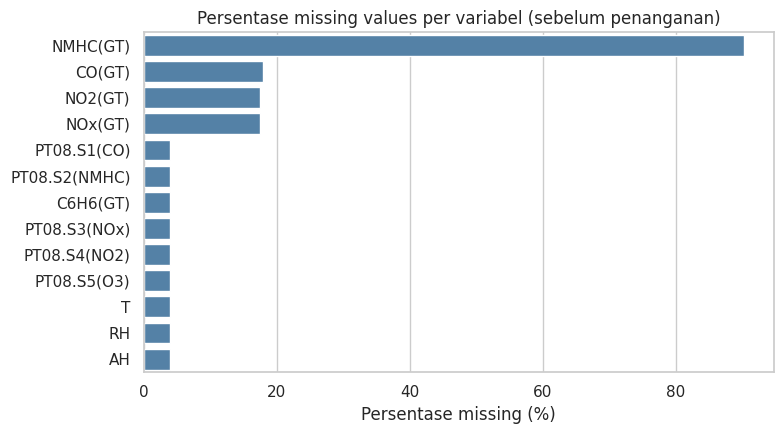

In [7]:
missing_table = pd.DataFrame({
    "missing_count": df[existing_meas].isna().sum(),
    "missing_pct": df[existing_meas].isna().mean() * 100,
}).sort_values("missing_pct", ascending=False)

display(missing_table.round(2))
missing_table.to_csv(f"{OUT}/missing_values_before.csv")

all_na_rows = int(df[existing_meas].isna().all(axis=1).sum())
print(f"\nBaris dengan SEMUA variabel pengukuran kosong: {all_na_rows} "
      f"({all_na_rows / len(df) * 100:.2f}%)")

plt.figure(figsize=(8, 4.5))
sns.barplot(x=missing_table["missing_pct"], y=missing_table.index, color="steelblue")
plt.xlabel("Persentase missing (%)")
plt.ylabel("")
plt.title("Persentase missing values per variabel (sebelum penanganan)")
plt.tight_layout()
savefig("missing_before_bar")
plt.show()

## Data duplikat dan inkonsistensi format (A.2.2 dan A.2.3)
Memeriksa duplikat (seluruh baris dan berdasarkan `datetime`), konsistensi format tanggal/waktu/desimal/nama kolom, kewajaran rentang nilai, serta kelengkapan deret waktu per jam.

In [8]:
# ---- A.2.2 Duplikat
dup_full = int(df.duplicated(subset=list(df_raw.columns)).sum())
dup_dt = int(df.duplicated(subset=["datetime"]).sum())
print("Duplikat seluruh baris           :", dup_full)
print("Duplikat berdasarkan datetime    :", dup_dt)

df = df.drop_duplicates(subset=list(df_raw.columns)).copy()
df = df.drop_duplicates(subset=["datetime"], keep="first").copy()
print("Dimensi setelah hapus duplikat   :", df.shape)

# ---- A.2.3 Inkonsistensi format
date_str = df["Date"].astype(str).str.strip()
time_str = df["Time"].astype(str).str.strip()
bad_date_fmt = int((~date_str.str.match(r"^\d{2}/\d{2}/\d{4}$")).sum())
bad_time_fmt = int((~time_str.str.match(r"^\d{2}\.\d{2}\.\d{2}$")).sum())
colon_time = int(time_str.str.contains(":").sum())
space_cols = [c for c in load_info["raw_columns"] if c != c.strip()]

print("\n[Format] Date tidak berpola dd/mm/yyyy :", bad_date_fmt)
print("[Format] Time tidak berpola HH.MM.SS   :", bad_time_fmt, f"(memakai titik dua: {colon_time})")
print("[Format] Nama kolom bersepasi berlebih  :", space_cols if space_cols else "tidak ada")
print("[Format] Desimal pada berkas memakai koma, waktu memakai titik: format non-standar, sudah dinormalkan")

# ---- Kewajaran rentang nilai
conc_cols = [c for c in ["CO(GT)", "NMHC(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"] if c in df.columns]
neg_conc = int((df[conc_cols] < 0).sum().sum())
rh_bad = int(((df["RH"] < 0) | (df["RH"] > 100)).sum())
ah_bad = int((df["AH"] <= 0).sum())
print("\n[Rentang] Konsentrasi bernilai negatif :", neg_conc)
print("[Rentang] RH di luar 0-100             :", rh_bad)
print("[Rentang] AH <= 0                      :", ah_bad)

# ---- Kelengkapan deret waktu per jam
ts = pd.DatetimeIndex(df["datetime"].sort_values())
expected = pd.date_range(ts.min(), ts.max(), freq="h")
missing_ts = int(len(expected.difference(ts)))
print("\n[Waktu] Timestamp per jam yang hilang di rentang data:", missing_ts)

print("\n[Skala] Satuan antarvariabel berbeda (mg/m3, ug/m3, ppb, C, %, g/m3, respons sensor)")
print("        sehingga standardisasi/normalisasi diperlukan pada PCA dan K-Means.")

Duplikat seluruh baris           : 0
Duplikat berdasarkan datetime    : 0
Dimensi setelah hapus duplikat   : (9357, 18)

[Format] Date tidak berpola dd/mm/yyyy : 0
[Format] Time tidak berpola HH.MM.SS   : 0 (memakai titik dua: 0)
[Format] Nama kolom bersepasi berlebih  : tidak ada
[Format] Desimal pada berkas memakai koma, waktu memakai titik: format non-standar, sudah dinormalkan

[Rentang] Konsentrasi bernilai negatif : 0
[Rentang] RH di luar 0-100             : 0
[Rentang] AH <= 0                      : 0

[Waktu] Timestamp per jam yang hilang di rentang data: 0

[Skala] Satuan antarvariabel berbeda (mg/m3, ug/m3, ppb, C, %, g/m3, respons sensor)
        sehingga standardisasi/normalisasi diperlukan pada PCA dan K-Means.


## Tabel ringkasan masalah kualitas data (A.2.4)
Merangkum seluruh temuan Sel 4, 7, dan 7 ke dalam satu tabel beserta penanganannya.

In [9]:
mt = missing_table
def pct(c): return f"{mt.loc[c, 'missing_pct']:.1f}%"

ref_vars = [c for c in ["CO(GT)", "NOx(GT)", "NO2(GT)"] if c in mt.index]
sensor_vars = [c for c in existing_meas if c not in ["NMHC(GT)"] + ref_vars]

quality_rows = [
    ["Kode penanda -200 sebagai missing", "Seluruh variabel pengukuran",
     f"{int(sentinel_count.sum())} nilai -200", "Diubah menjadi NaN"],
    ["Baris/kolom kosong pada berkas", "Seluruh dataset",
     f"{load_info['n_blank_rows']} baris, {load_info['n_blank_cols']} kolom", "Dibuang"],
    ["Missing sangat tinggi", "NMHC(GT)" if "NMHC(GT)" in mt.index else "-",
     pct("NMHC(GT)") if "NMHC(GT)" in mt.index else "-", "Kolom dikeluarkan (> 40%)"],
    ["Missing sedang (analyzer referensi)", ", ".join(ref_vars),
     ", ".join(f"{c}: {pct(c)}" for c in ref_vars), "Interpolasi gap pendek, median per jam untuk gap panjang"],
    ["Missing rendah (sensor, cuaca)", ", ".join(sensor_vars),
     f"sekitar {mt.loc[sensor_vars, 'missing_pct'].mean():.1f}% per variabel",
     "Interpolasi gap pendek, median per jam untuk gap panjang"],
    ["Baris dengan semua sensor kosong", "Seluruh variabel pengukuran",
     f"{all_na_rows} baris", "Diisi lewat strategi di atas (gagal alat serempak)"],
    ["Data duplikat", "Seluruh baris / datetime", f"{dup_full} / {dup_dt}", "Tidak ada yang perlu dihapus"],
    ["Format tanggal-waktu non-standar", "Date, Time",
     f"Date tak sesuai: {bad_date_fmt}; Time tak sesuai: {bad_time_fmt}",
     "Diparse manual menjadi datetime"],
    ["Format angka berkoma desimal", "Variabel numerik", "Seluruh kolom numerik", "decimal=',' saat membaca data"],
    ["Rentang nilai tidak wajar", "Konsentrasi, RH, AH",
     f"negatif: {neg_conc}; RH invalid: {rh_bad}; AH<=0: {ah_bad}", "Tidak ada penanganan khusus"],
    ["Timestamp per jam hilang", "datetime", f"{missing_ts} jam", "Dicatat; tidak dibuat baris baru"],
    ["Satuan dan skala berbeda antarvariabel", "Seluruh variabel numerik",
     "mg/m3, ug/m3, ppb, C, %, g/m3, respons sensor", "Standardisasi sebelum PCA dan K-Means"],
    ["Outlier", "Lihat Sel 13", "Dihitung dengan metode IQR pada Sel 13", "Keputusan dijelaskan pada Sel 14"],
]
quality_summary = pd.DataFrame(quality_rows, columns=["Masalah kualitas data", "Variabel terdampak", "Temuan", "Penanganan"])
quality_summary.index = np.arange(1, len(quality_summary) + 1)
quality_summary.index.name = "No"
display(quality_summary)
quality_summary.to_csv(f"{OUT}/ringkasan_masalah_kualitas.csv")

,Masalah kualitas data,Variabel terdampak,Temuan,Penanganan
No,,,,
1,Kode penanda -200 sebagai missing,Seluruh variabel pengukuran,16701 nilai -200,Diubah menjadi NaN
2,Baris/kolom kosong pada berkas,Seluruh dataset,"114 baris, 2 kolom",Dibuang
3,Missing sangat tinggi,NMHC(GT),90.2%,Kolom dikeluarkan (> 40%)
4,Missing sedang (analyzer referensi),"CO(GT), NOx(GT), NO2(GT)","CO(GT): 18.0%, NOx(GT): 17.5%, NO2(GT): 17.5%","Interpolasi gap pendek, median per jam untuk g..."
5,"Missing rendah (sensor, cuaca)","PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), PT08.S3(...",sekitar 3.9% per variabel,"Interpolasi gap pendek, median per jam untuk g..."
6,Baris dengan semua sensor kosong,Seluruh variabel pengukuran,31 baris,Diisi lewat strategi di atas (gagal alat serem...
7,Data duplikat,Seluruh baris / datetime,0 / 0,Tidak ada yang perlu dihapus
8,Format tanggal-waktu non-standar,"Date, Time",Date tak sesuai: 0; Time tak sesuai: 0,Diparse manual menjadi datetime
9,Format angka berkoma desimal,Variabel numerik,Seluruh kolom numerik,"decimal=',' saat membaca data"


## B.1 Penanganan Missing Values
**Alasan strategi.** Data adalah deret waktu per jam dengan pola harian yang kuat (lalu lintas, suhu). Karena itu:

1. Kolom dengan missing di atas 40% dikeluarkan, sebab imputasi pada kondisi tersebut lebih banyak menciptakan data buatan daripada mengembalikan informasi asli.
2. Untuk gap pendek (sampai 6 jam berturut-turut), dipakai **interpolasi linear berbasis waktu**, karena nilai antar jam bersebelahan sangat berkaitan.
3. Untuk gap panjang, interpolasi linear akan membuat garis lurus buatan yang menutupi pola harian, sehingga dipakai **median per jam dalam sehari**, yang mempertahankan pola harian dan tahan terhadap outlier.
4. Sisa terakhir (jika masih ada) diisi dengan **median keseluruhan**.

##  Menentukan strategi missing values per variabel (B.1.1)
Mendefinisikan fungsi bantu, menghitung panjang gap terpanjang tiap variabel, lalu menyusun tabel strategi beserta alasannya.

In [10]:
MAX_GAP = 6  # jam; gap <= MAX_GAP diisi interpolasi, sisanya median per jam

missing_pct = df[existing_meas].isna().mean() * 100
high_missing_cols = missing_pct[missing_pct > 40].index.tolist()

df_analytic = (df.drop(columns=high_missing_cols)
                 .sort_values("datetime")
                 .set_index("datetime"))
analytic_meas = [c for c in existing_meas if c in df_analytic.columns]

def gap_lengths(s):
    """Panjang gap NaN berturut-turut pada setiap posisi NaN (0 jika bukan NaN)."""
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    return isna.groupby(grp).transform("sum").where(isna, 0)

def fill_short_gaps(s, max_gap=MAX_GAP):
    """Interpolasi berbasis waktu hanya untuk gap sepanjang <= max_gap."""
    gl = gap_lengths(s)
    interp = s.interpolate(method="time", limit_area="inside")
    mask = (gl > 0) & (gl <= max_gap)
    return s.where(~mask, interp)

rows = []
for c in existing_meas:
    pct_c = float(missing_pct[c])
    if c in high_missing_cols:
        strategy = "Hapus kolom"
        reason = "Missing > 40%: imputasi akan didominasi data buatan."
        longest = np.nan
    else:
        longest = int(gap_lengths(df_analytic[c]).max())
        strategy = f"Interpolasi waktu (gap <= {MAX_GAP} jam) + median per jam"
        if pct_c > 10:
            reason = "Missing sedang; pola harian kuat sehingga gap panjang diisi median per jam."
        else:
            reason = "Missing rendah; gap pendek diinterpolasi, sisanya median per jam."
    rows.append([c, round(pct_c, 2), longest, strategy, reason])

strategy_table = pd.DataFrame(rows, columns=["Variabel", "Missing (%)", "Gap terpanjang (jam)", "Strategi", "Alasan"])
display(strategy_table)
strategy_table.to_csv(f"{OUT}/strategi_missing.csv", index=False)
print("Kolom dikeluarkan:", high_missing_cols)

,Variabel,Missing (%),Gap terpanjang (jam),Strategi,Alasan
0,CO(GT),17.99,173.0,Interpolasi waktu (gap <= 6 jam) + median per jam,Missing sedang; pola harian kuat sehingga gap ...
1,PT08.S1(CO),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."
2,NMHC(GT),90.23,NaN,Hapus kolom,Missing > 40%: imputasi akan didominasi data b...
3,C6H6(GT),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."
4,PT08.S2(NMHC),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."
5,NOx(GT),17.52,173.0,Interpolasi waktu (gap <= 6 jam) + median per jam,Missing sedang; pola harian kuat sehingga gap ...
6,PT08.S3(NOx),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."
7,NO2(GT),17.55,173.0,Interpolasi waktu (gap <= 6 jam) + median per jam,Missing sedang; pola harian kuat sehingga gap ...
8,PT08.S4(NO2),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."
9,PT08.S5(O3),3.91,76.0,Interpolasi waktu (gap <= 6 jam) + median per jam,"Missing rendah; gap pendek diinterpolasi, sisa..."


Kolom dikeluarkan: ['NMHC(GT)']


##  Menerapkan strategi missing values dan verifikasi (B.1.2 dan B.1.3)
Menerapkan strategi pada Sel 10, menampilkan kondisi **sebelum dan sesudah**, dan memverifikasi bahwa tidak ada lagi missing values.

,Variabel,Missing awal,Diisi interpolasi,Diisi median per jam,Diisi median total
0,CO(GT),1683,188,1495,0
1,PT08.S1(CO),366,15,351,0
2,C6H6(GT),366,15,351,0
3,PT08.S2(NMHC),366,15,351,0
4,NOx(GT),1639,325,1314,0
5,PT08.S3(NOx),366,15,351,0
6,NO2(GT),1642,326,1316,0
7,PT08.S4(NO2),366,15,351,0
8,PT08.S5(O3),366,15,351,0
9,T,366,15,351,0


,missing_sebelum,missing_sesudah,mean_sebelum,mean_sesudah,std_sebelum,std_sesudah
CO(GT),1683,0,2.153,2.087,1.453,1.377
PT08.S1(CO),366,0,1099.833,1099.468,217.080,214.126
C6H6(GT),366,0,10.083,10.062,7.450,7.350
PT08.S2(NMHC),366,0,939.153,939.304,266.831,263.678
NOx(GT),1639,0,246.897,233.542,212.979,198.915
PT08.S3(NOx),366,0,835.494,834.049,256.817,253.115
NO2(GT),1642,0,113.091,110.775,48.370,46.174
PT08.S4(NO2),366,0,1456.265,1457.622,346.207,340.327
PT08.S5(O3),366,0,1022.906,1022.880,398.484,392.977
T,366,0,18.318,18.314,8.832,8.684



Total missing setelah penanganan: 0
VERIFIKASI: BERHASIL, tidak ada missing values


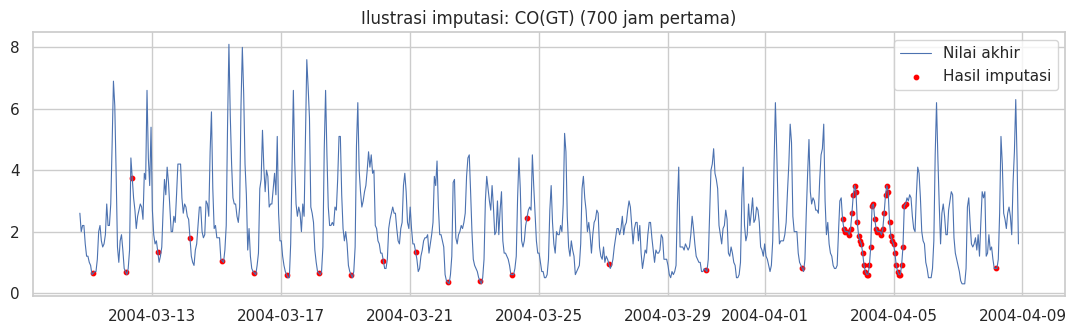

In [11]:
snapshot = df_analytic[analytic_meas].copy()   # kondisi SEBELUM
fill_log = []

for c in analytic_meas:
    s0 = snapshot[c]
    n_na = int(s0.isna().sum())

    s1 = fill_short_gaps(s0)                                  # tahap 1: interpolasi gap pendek
    n_interp = n_na - int(s1.isna().sum())

    hourly_med = s0.groupby(s0.index.hour).transform("median")
    s2 = s1.fillna(hourly_med)                                # tahap 2: median per jam
    n_hour = int(s1.isna().sum()) - int(s2.isna().sum())

    s3 = s2.fillna(s0.median())                               # tahap 3: median keseluruhan
    n_med = int(s2.isna().sum()) - int(s3.isna().sum())

    df_analytic[c] = s3
    fill_log.append([c, n_na, n_interp, n_hour, n_med])

fill_log = pd.DataFrame(fill_log, columns=["Variabel", "Missing awal", "Diisi interpolasi", "Diisi median per jam", "Diisi median total"])
display(fill_log)

# ---- Perbandingan sebelum vs sesudah
compare_missing = pd.DataFrame({
    "missing_sebelum": snapshot.isna().sum(),
    "missing_sesudah": df_analytic[analytic_meas].isna().sum(),
    "mean_sebelum": snapshot.mean(),
    "mean_sesudah": df_analytic[analytic_meas].mean(),
    "std_sebelum": snapshot.std(),
    "std_sesudah": df_analytic[analytic_meas].std(),
})
display(compare_missing.round(3))
compare_missing.to_csv(f"{OUT}/missing_values_before_after.csv")

# ---- Verifikasi
total_missing_after = int(df_analytic[analytic_meas].isna().sum().sum())
print("\nTotal missing setelah penanganan:", total_missing_after)
print("VERIFIKASI:", "BERHASIL, tidak ada missing values" if total_missing_after == 0 else "MASIH ADA missing values!")

# ---- Ilustrasi imputasi pada salah satu variabel
example = "CO(GT)" if "CO(GT)" in analytic_meas else analytic_meas[0]
n_show = min(700, len(df_analytic))
idx = snapshot.index[:n_show]
vals = df_analytic[example].values[:n_show]
was_na = snapshot[example].isna().values[:n_show]
plt.figure(figsize=(11, 3.5))
plt.plot(idx, vals, lw=0.8, label="Nilai akhir")
plt.scatter(idx[was_na], vals[was_na], color="red", s=10, label="Hasil imputasi")
plt.title(f"Ilustrasi imputasi: {example} ({n_show} jam pertama)")
plt.legend()
plt.tight_layout()
savefig("ilustrasi_imputasi")
plt.show()

df_analytic = df_analytic.reset_index()

##  Variabel kategorik turunan: `day_type`, `time_period`, `season`
Dataset asli hanya berisi variabel numerik dan waktu, sehingga variabel kategorik diturunkan dari kolom `datetime`. Variabel ini dipakai pada Bagian C.2, D.2, dan D.3. Variabel `season` sengaja ditambahkan karena sebarannya tidak otomatis seimbang (data mulai Maret 2004 sampai April 2005), sehingga analisis *class imbalance* menjadi lebih bermakna.

In [12]:
dt_ = df_analytic["datetime"]
df_analytic["hour"] = dt_.dt.hour

df_analytic["day_type"] = pd.Categorical(
    np.where(dt_.dt.dayofweek >= 5, "Akhir pekan", "Hari kerja"),
    categories=["Hari kerja", "Akhir pekan"], ordered=False)

df_analytic["time_period"] = pd.cut(
    df_analytic["hour"], bins=[-1, 5, 11, 17, 23],
    labels=["Dini hari", "Pagi", "Siang", "Malam"], ordered=True)

season_map = {12: "Musim Dingin", 1: "Musim Dingin", 2: "Musim Dingin",
              3: "Musim Semi", 4: "Musim Semi", 5: "Musim Semi",
              6: "Musim Panas", 7: "Musim Panas", 8: "Musim Panas",
              9: "Musim Gugur", 10: "Musim Gugur", 11: "Musim Gugur"}
df_analytic["season"] = pd.Categorical(
    dt_.dt.month.map(season_map),
    categories=["Musim Semi", "Musim Panas", "Musim Gugur", "Musim Dingin"], ordered=False)

for c in ["day_type", "time_period", "season"]:
    print(f"\n{c}:")
    print(df_analytic[c].value_counts().sort_index().to_string())


day_type:
day_type
Hari kerja     6669
Akhir pekan    2688

time_period:
time_period
Dini hari    2340
Pagi         2340
Siang        2337
Malam        2340

season:
season
Musim Semi      2805
Musim Panas     2208
Musim Gugur     2184
Musim Dingin    2160


## B.2 Penanganan Outlier
Outlier diidentifikasi dengan metode IQR (batas bawah = Q1 − 1,5·IQR, batas atas = Q3 + 1,5·IQR) pada enam variabel numerik.

## Identifikasi outlier dengan metode IQR (B.2.1 dan B.2.2)
Menghitung Q1, Q3, IQR, batas bawah, batas atas, jumlah dan persentase outlier untuk enam variabel, disertai boxplot sebelum penanganan.

,variable,Q1,Q3,IQR,lower_bound,upper_bound,n_outlier_bawah,n_outlier_atas,n_outlier,pct_outlier
0,CO(GT),1.0,2.8,1.8,-1.70,5.50,0,242,242,2.586
1,C6H6(GT),4.5,13.9,9.4,-9.60,28.00,0,240,240,2.565
2,NOx(GT),99.0,297.0,198.0,-198.00,594.00,0,607,607,6.487
3,NO2(GT),77.0,137.0,60.0,-13.00,227.00,0,156,156,1.667
4,T,12.0,24.1,12.1,-6.15,42.25,0,10,10,0.107
5,RH,35.8,62.0,26.2,-3.50,101.30,0,0,0,0.000


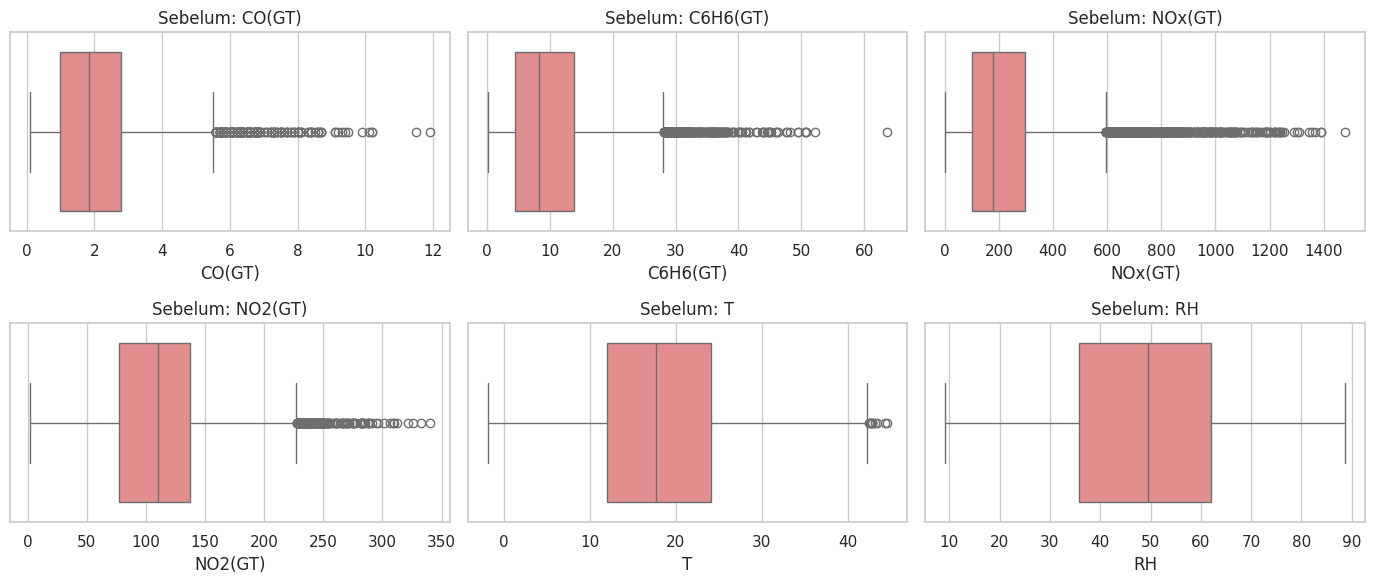

In [13]:
outlier_vars = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH"] if c in df_analytic.columns]

def iqr_outlier_table(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_low = int((s < lo).sum())
        n_high = int((s > hi).sum())
        rows.append({
            "variable": c, "Q1": q1, "Q3": q3, "IQR": iqr,
            "lower_bound": lo, "upper_bound": hi,
            "n_outlier_bawah": n_low, "n_outlier_atas": n_high,
            "n_outlier": n_low + n_high,
            "pct_outlier": (n_low + n_high) / len(s) * 100,
        })
    return pd.DataFrame(rows)

outlier_table = iqr_outlier_table(df_analytic, outlier_vars)
display(outlier_table.round(3))
outlier_table.to_csv(f"{OUT}/outlier_iqr.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), outlier_vars):
    sns.boxplot(x=df_analytic[c], ax=ax, color="lightcoral")
    ax.set_title(f"Sebelum: {c}")
for ax in axes.ravel()[len(outlier_vars):]:
    ax.axis("off")
plt.tight_layout()
savefig("boxplot_sebelum_outlier")
plt.show()

## Keputusan outlier dan winsorization berbasis batas IQR (B.2.3)
**Keputusan.**

- **Analisis deskriptif, univariat, dan bivariat:** outlier **dipertahankan**. Nilai polutan yang tinggi (misalnya CO dan NOx saat jam sibuk) adalah kejadian nyata yang secara fisik valid, bukan kesalahan input. Menghapusnya akan membuang informasi tentang episode pencemaran.
- **PCA dan K-Means:** nilai dibatasi (**winsorization**) pada batas bawah/atas IQR. Kedua metode ini sensitif terhadap nilai ekstrem (PCA lewat varians, K-Means lewat jarak). Batas yang dipakai sama dengan batas pada Sel 13, sehingga metode identifikasi dan penanganan konsisten. Variabel tanpa outlier tidak berubah.
- Penghapusan baris tidak dipilih karena akan memutus kontinuitas deret waktu per jam.

,Variabel,Batas bawah,Batas atas,Nilai di-cap,% di-cap
0,CO(GT),-1.700,5.500,242,2.59
1,C6H6(GT),-9.600,28.000,240,2.56
2,NOx(GT),-198.000,594.000,607,6.49
3,NO2(GT),-13.000,227.000,156,1.67
4,T,-6.150,42.250,10,0.11
5,RH,-3.500,101.300,0,0.00
6,AH,-0.082,2.126,6,0.06


,mean_sebelum,mean_sesudah,std_sebelum,std_sesudah,max_sebelum,max_sesudah
CO(GT),2.087,2.056,1.377,1.271,11.900,5.500
C6H6(GT),10.062,9.905,7.350,6.825,63.700,28.000
NOx(GT),233.542,220.795,198.915,160.640,1479.000,594.000
NO2(GT),110.775,110.336,46.174,44.821,340.000,227.000
T,18.314,18.313,8.684,8.682,44.600,42.250
RH,49.168,49.168,17.108,17.108,88.700,88.700
AH,1.025,1.024,0.396,0.396,2.231,2.126


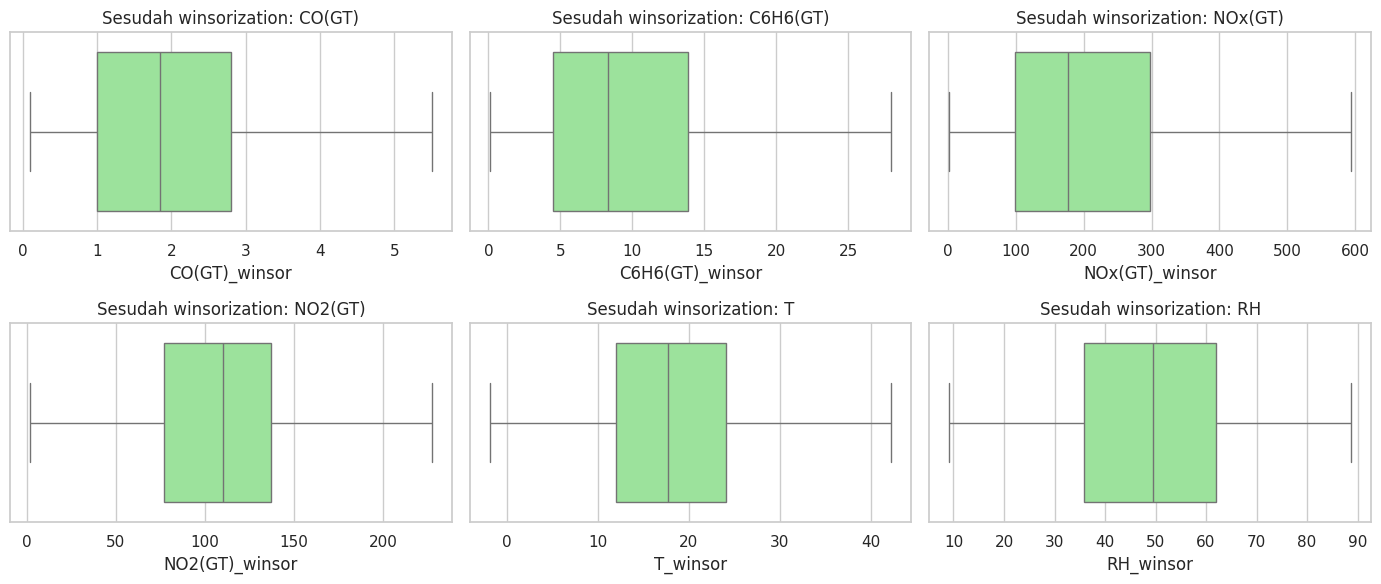

In [14]:
pca_features = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"] if c in df_analytic.columns]

iqr_bounds = {}
cap_rows = []
for c in pca_features:
    s = df_analytic[c]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_bounds[c] = (lo, hi)
    df_analytic[f"{c}_winsor"] = s.clip(lo, hi)
    n_cap = int(((s < lo) | (s > hi)).sum())
    cap_rows.append([c, round(lo, 3), round(hi, 3), n_cap, round(n_cap / len(s) * 100, 2)])

cap_table = pd.DataFrame(cap_rows, columns=["Variabel", "Batas bawah", "Batas atas", "Nilai di-cap", "% di-cap"])
display(cap_table)
cap_table.to_csv(f"{OUT}/winsorization_iqr.csv", index=False)

compare_outlier = pd.DataFrame({
    "mean_sebelum": [df_analytic[c].mean() for c in pca_features],
    "mean_sesudah": [df_analytic[f"{c}_winsor"].mean() for c in pca_features],
    "std_sebelum": [df_analytic[c].std() for c in pca_features],
    "std_sesudah": [df_analytic[f"{c}_winsor"].std() for c in pca_features],
    "max_sebelum": [df_analytic[c].max() for c in pca_features],
    "max_sesudah": [df_analytic[f"{c}_winsor"].max() for c in pca_features],
}, index=pca_features)
display(compare_outlier.round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), outlier_vars):
    sns.boxplot(x=df_analytic[f"{c}_winsor"], ax=ax, color="lightgreen")
    ax.set_title(f"Sesudah winsorization: {c}")
for ax in axes.ravel()[len(outlier_vars):]:
    ax.axis("off")
plt.tight_layout()
savefig("boxplot_sesudah_winsorization")
plt.show()

## B.3 Transformasi Data
**Mengapa normalisasi diperlukan.** `CO(GT)` (0–12 mg/m3), `NOx(GT)` (0–1.500 ppb), `T` (−2–45 °C), dan `RH` (9–89 %) berbeda skala sangat jauh. Tanpa penyamaan skala, variabel berskala besar (NOx) mendominasi perhitungan jarak (K-Means) dan varians (PCA). Min-Max dipakai agar semua variabel berada pada rentang [0, 1], sedangkan Z-Score dipakai agar mean = 0 dan simpangan baku = 1. Keduanya diterapkan pada versi winsorized supaya satu nilai ekstrem tidak menentukan rentang Min-Max.

## Normalisasi Min-Max dan Z-Score (B.3.1)
Menormalisasi empat variabel numerik (`CO(GT)`, `NOx(GT)`, `T`, `RH`) dengan Min-Max dan Z-Score.

In [15]:
transform_vars = [c for c in ["CO(GT)", "NOx(GT)", "T", "RH"] if c in df_analytic.columns]
winsor_cols = [f"{c}_winsor" for c in transform_vars]

df_analytic[[f"{c}_minmax" for c in transform_vars]] = MinMaxScaler().fit_transform(df_analytic[winsor_cols])
df_analytic[[f"{c}_z" for c in transform_vars]] = StandardScaler().fit_transform(df_analytic[winsor_cols])

print("Variabel dinormalisasi:", transform_vars)
display(df_analytic[[f"{c}_minmax" for c in transform_vars]].describe().T)
display(df_analytic[[f"{c}_z" for c in transform_vars]].describe().T)

Variabel dinormalisasi: ['CO(GT)', 'NOx(GT)', 'T', 'RH']


,count,mean,std,min,25%,50%,75%,max
CO(GT)_minmax,9357.0,0.362299,0.235316,0.0,0.166667,0.324074,0.500000,1.0
NOx(GT)_minmax,9357.0,0.369586,0.271351,0.0,0.163851,0.295608,0.498311,1.0
T_minmax,9357.0,0.457828,0.196640,0.0,0.314836,0.443941,0.588901,1.0
RH_minmax,9357.0,0.502741,0.215190,0.0,0.334591,0.506918,0.664151,1.0


,count,mean,std,min,25%,50%,75%,max
CO(GT)_z,9357.0,2.885607e-16,1.000053,-1.539710,-0.831404,-0.162448,0.585209,2.710127
NOx(GT)_z,9357.0,-3.644977e-17,1.000053,-1.362092,-0.758225,-0.272642,0.474410,2.323363
T_z,9357.0,-8.504947e-17,1.000053,-2.328381,-0.727219,-0.070627,0.666599,2.757326
RH_z,9357.0,-1.214992e-16,1.000053,-2.336390,-0.781443,0.019414,0.750122,2.310915


## Diskretisasi variabel kontinu (B.3.2)
Dua variabel kontinu didiskretisasi:

- `CO(GT)` menjadi `CO_level` (4 kategori) dengan **metode statistik** (kuartil), sehingga setiap kategori mewakili sekitar seperempat data.
- `T` menjadi `T_category` (4 kategori) dengan **pengetahuan domain** (ambang suhu lazim: di bawah 10 °C dingin, 10–20 sejuk, 20–30 hangat, 30 °C ke atas panas).

In [16]:
# --- Metode statistik: kuartil
co_labels = ["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
co_cat, co_bins = pd.qcut(df_analytic["CO(GT)"], q=4, labels=co_labels, retbins=True)
df_analytic["CO_level"] = pd.Categorical(co_cat, categories=co_labels, ordered=True)

print("Batas kategori CO_level (kuartil CO(GT), mg/m3):")
for i, lab in enumerate(co_labels):
    print(f"  {lab:<14}: {co_bins[i]:.2f} s.d. {co_bins[i+1]:.2f}")

# --- Metode domain knowledge: ambang suhu
t_labels = ["Dingin", "Sejuk", "Hangat", "Panas"]
df_analytic["T_category"] = pd.cut(
    df_analytic["T"], bins=[-np.inf, 10, 20, 30, np.inf],
    labels=t_labels, right=False, ordered=True)

print("\nBatas kategori T_category (derajat Celsius): Dingin < 10 <= Sejuk < 20 <= Hangat < 30 <= Panas")

for c in ["CO_level", "T_category"]:
    print(f"\nDistribusi {c}:")
    print(df_analytic[c].value_counts().sort_index().to_string())

Batas kategori CO_level (kuartil CO(GT), mg/m3):
  Rendah        : 0.10 s.d. 1.00
  Sedang        : 1.00 s.d. 1.85
  Tinggi        : 1.85 s.d. 2.80
  Sangat Tinggi : 2.80 s.d. 11.90

Batas kategori T_category (derajat Celsius): Dingin < 10 <= Sejuk < 20 <= Hangat < 30 <= Panas

Distribusi CO_level:
CO_level
Rendah           2343
Sedang           2370
Tinggi           2393
Sangat Tinggi    2251

Distribusi T_category:
T_category
Dingin    1670
Sejuk     3816
Hangat    2917
Panas      954


## Statistik deskriptif sebelum dan sesudah transformasi (B.3.3)
Membandingkan statistik variabel asli dengan hasil Min-Max, Z-Score, dan kategori hasil diskretisasi.

In [17]:
before = df_analytic[winsor_cols].describe().T[["mean", "std", "min", "max"]]
before.index = transform_vars
after_mm = df_analytic[[f"{c}_minmax" for c in transform_vars]].describe().T[["mean", "std", "min", "max"]]
after_mm.index = transform_vars
after_z = df_analytic[[f"{c}_z" for c in transform_vars]].describe().T[["mean", "std", "min", "max"]]
after_z.index = transform_vars

print("SEBELUM transformasi (nilai asli setelah winsorization):")
display(before.round(3))
print("SESUDAH Min-Max (rentang 0-1):")
display(after_mm.round(3))
print("SESUDAH Z-Score (mean = 0, std = 1):")
display(after_z.round(3))

print("Statistik CO(GT) per kategori CO_level (hasil diskretisasi):")
display(df_analytic.groupby("CO_level", observed=True)["CO(GT)"].agg(["count", "min", "mean", "max"]).round(2))
print("Statistik T per kategori T_category (hasil diskretisasi):")
display(df_analytic.groupby("T_category", observed=True)["T"].agg(["count", "min", "mean", "max"]).round(2))

before.to_csv(f"{OUT}/transformasi_sebelum.csv")
after_mm.to_csv(f"{OUT}/transformasi_minmax.csv")
after_z.to_csv(f"{OUT}/transformasi_zscore.csv")

SEBELUM transformasi (nilai asli setelah winsorization):


,mean,std,min,max
CO(GT),2.056,1.271,0.1,5.50
NOx(GT),220.795,160.640,2.0,594.00
T,18.313,8.682,-1.9,42.25
RH,49.168,17.108,9.2,88.70


SESUDAH Min-Max (rentang 0-1):


,mean,std,min,max
CO(GT),0.362,0.235,0.0,1.0
NOx(GT),0.370,0.271,0.0,1.0
T,0.458,0.197,0.0,1.0
RH,0.503,0.215,0.0,1.0


SESUDAH Z-Score (mean = 0, std = 1):


,mean,std,min,max
CO(GT),0.0,1.0,-1.540,2.710
NOx(GT),-0.0,1.0,-1.362,2.323
T,-0.0,1.0,-2.328,2.757
RH,-0.0,1.0,-2.336,2.311


Statistik CO(GT) per kategori CO_level (hasil diskretisasi):


,count,min,mean,max
CO_level,,,,
Rendah,2343,0.10,0.68,1.00
Sedang,2370,1.05,1.46,1.85
Tinggi,2393,1.90,2.26,2.80
Sangat Tinggi,2251,2.85,4.03,11.90


Statistik T per kategori T_category (hasil diskretisasi):


,count,min,mean,max
T_category,,,,
Dingin,1670,-1.9,6.31,9.93
Sejuk,3816,10.0,15.03,19.90
Hangat,2917,20.0,24.15,29.90
Panas,954,30.0,34.63,44.60


## C.1 Analisis Variabel Numerik (Univariat)

##  Statistik deskriptif, histogram, boxplot, Q-Q plot, bentuk distribusi, dan normalitas (C.1)
Lima variabel numerik dianalisis: `CO(GT)`, `C6H6(GT)`, `NOx(GT)`, `T`, `RH`. Untuk tiap variabel dihitung seluruh statistik yang diminta, dibuat histogram dan boxplot (ditambah Q-Q plot), lalu bentuk distribusi dan kedekatan dengan normal diinterpretasikan otomatis dari skewness, kurtosis, dan uji normalitas D'Agostino. Analisis memakai data asli (outlier dipertahankan, sesuai keputusan Sel 14).

,variable,n,mean,median,mode,std,variance,IQR,min,max,skewness,kurtosis
0,CO(GT),9357,2.087,1.85,2.0,1.377,1.896,1.8,0.1,11.9,1.407,3.116
1,C6H6(GT),9357,10.062,8.30,2.8,7.350,54.017,9.4,0.1,63.7,1.368,2.592
2,NOx(GT),9357,233.542,177.00,219.0,198.915,39567.164,198.0,2.0,1479.0,1.897,4.471
3,T,9357,18.314,17.70,19.8,8.684,75.419,12.1,-1.9,44.6,0.315,-0.381
4,RH,9357,49.168,49.50,57.4,17.108,292.670,26.2,9.2,88.7,-0.032,-0.789


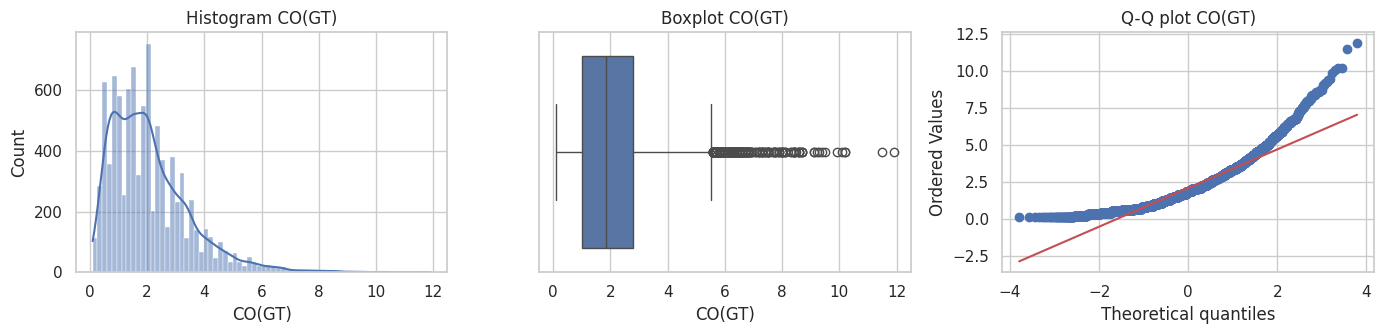

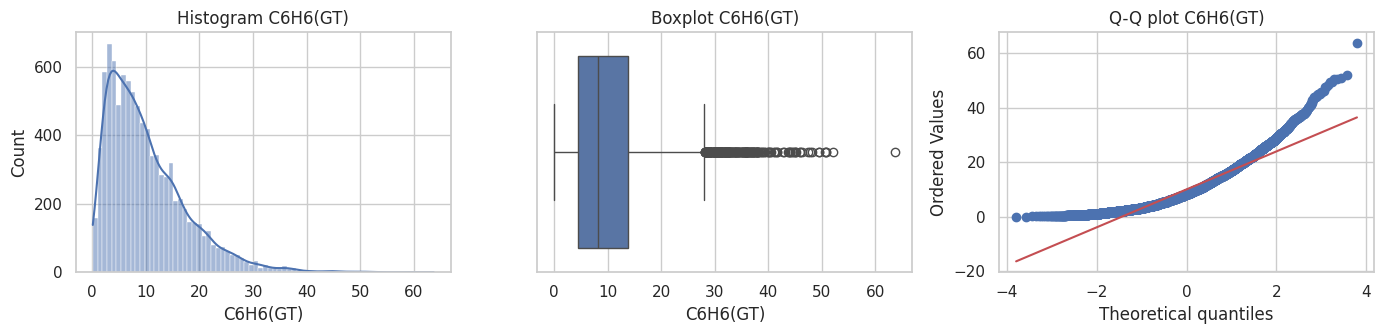

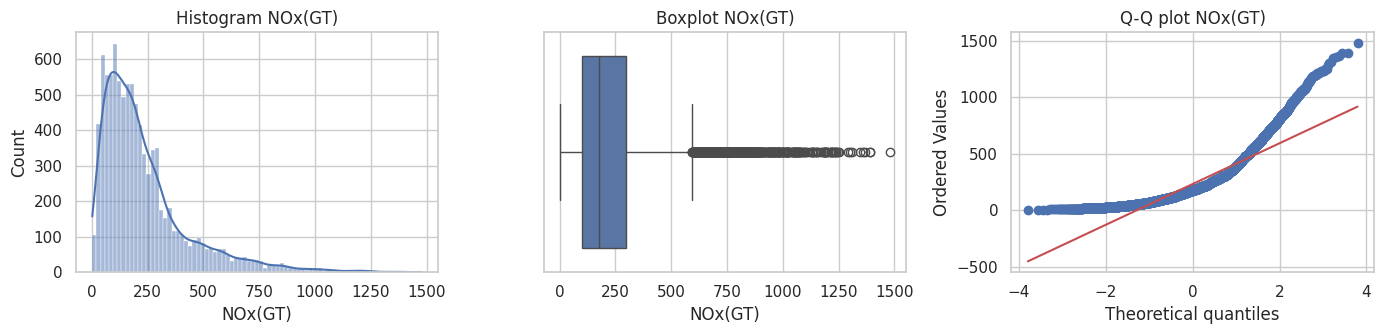

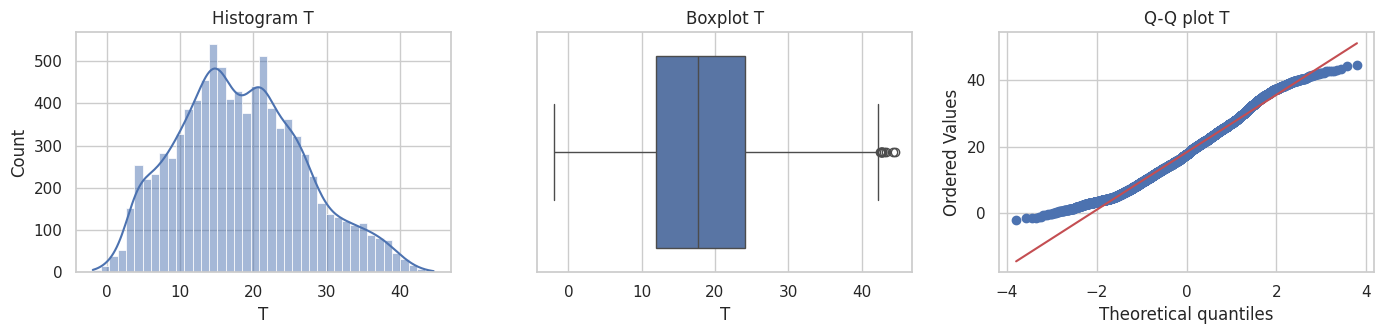

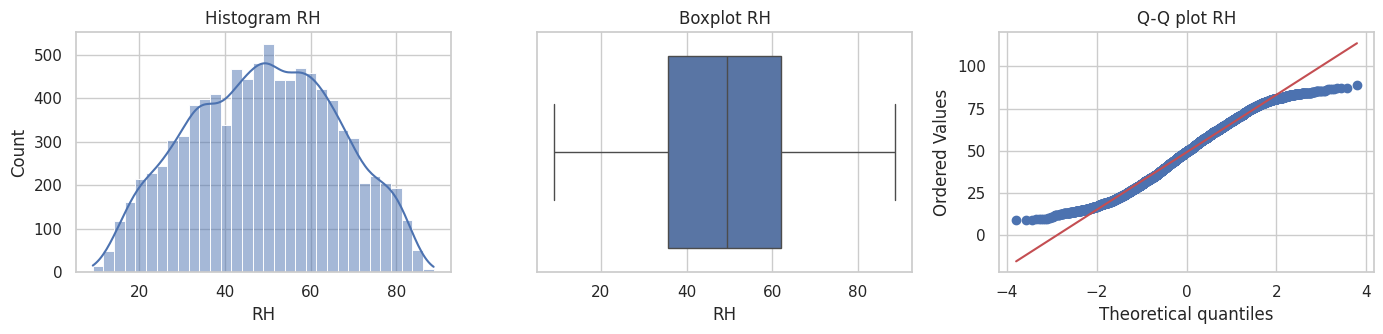


=== INTERPRETASI OTOMATIS BENTUK DISTRIBUSI DAN NORMALITAS ===


,Variabel,Skewness,Kurtosis,Bentuk distribusi,Ketebalan ekor,Uji D'Agostino,Mendekati normal?
0,CO(GT),1.407,3.116,right-skewed (kuat),leptokurtik (ekor lebih berat dari normal),p < 0.001,Tidak
1,C6H6(GT),1.368,2.592,right-skewed (kuat),leptokurtik (ekor lebih berat dari normal),p < 0.001,Tidak
2,NOx(GT),1.897,4.471,right-skewed (kuat),leptokurtik (ekor lebih berat dari normal),p < 0.001,Tidak
3,T,0.315,-0.381,simetris,mesokurtik (mirip normal),p < 0.001,Ya
4,RH,-0.032,-0.789,simetris,platikurtik (lebih datar dari normal),p < 0.001,Ya


Catatan: pada n besar, uji formal hampir selalu menolak normalitas; karena itu keputusan
'mendekati normal' juga mempertimbangkan |skewness| < 0.5, |kurtosis| < 1, dan Q-Q plot.


In [18]:
uni_vars = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "T", "RH"] if c in df_analytic.columns]

def univariate_stats(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        modes = s.mode()
        rows.append({
            "variable": c, "n": len(s), "mean": s.mean(), "median": s.median(),
            "mode": modes.iloc[0] if not modes.empty else np.nan,
            "std": s.std(), "variance": s.var(),
            "IQR": s.quantile(0.75) - s.quantile(0.25),
            "min": s.min(), "max": s.max(),
            "skewness": s.skew(), "kurtosis": s.kurtosis(),
        })
    return pd.DataFrame(rows)

uni_table = univariate_stats(df_analytic, uni_vars)
display(uni_table.round(3))
uni_table.to_csv(f"{OUT}/univariate_numeric.csv", index=False)

for c in uni_vars:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    sns.histplot(df_analytic[c], kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram {c}")
    sns.boxplot(x=df_analytic[c], ax=axes[1])
    axes[1].set_title(f"Boxplot {c}")
    stats.probplot(df_analytic[c], dist="norm", plot=axes[2])
    axes[2].set_title(f"Q-Q plot {c}")
    plt.tight_layout()
    savefig(f"univariat_{c}")
    plt.show()

def interpret_shape(skew, kurt):
    a = abs(skew)
    if a < 0.5:
        shape = "simetris"
    else:
        strength = "moderat" if a < 1 else "kuat"
        shape = f"right-skewed ({strength})" if skew > 0 else f"left-skewed ({strength})"
    if kurt > 0.5:
        k = "leptokurtik (ekor lebih berat dari normal)"
    elif kurt < -0.5:
        k = "platikurtik (lebih datar dari normal)"
    else:
        k = "mesokurtik (mirip normal)"
    return shape, k

print("\n=== INTERPRETASI OTOMATIS BENTUK DISTRIBUSI DAN NORMALITAS ===")
normality_rows = []
for _, r in uni_table.iterrows():
    c = r["variable"]
    shape, k = interpret_shape(r["skewness"], r["kurtosis"])
    stat, p = stats.normaltest(df_analytic[c].dropna())
    near_normal = (abs(r["skewness"]) < 0.5) and (abs(r["kurtosis"]) < 1)
    normality_rows.append([c, round(r["skewness"], 3), round(r["kurtosis"], 3), shape, k,
                           "p < 0.001" if p < 0.001 else f"p = {p:.3f}",
                           "Ya" if near_normal else "Tidak"])
normality_table = pd.DataFrame(normality_rows, columns=[
    "Variabel", "Skewness", "Kurtosis", "Bentuk distribusi", "Ketebalan ekor", "Uji D'Agostino", "Mendekati normal?"])
display(normality_table)
normality_table.to_csv(f"{OUT}/normalitas.csv", index=False)
print("Catatan: pada n besar, uji formal hampir selalu menolak normalitas; karena itu keputusan")
print("'mendekati normal' juga mempertimbangkan |skewness| < 0.5, |kurtosis| < 1, dan Q-Q plot.")

**Interpretasi C.1**

- **CO(GT), C6H6(GT), NOx(GT)** berdistribusi *right-skewed* (skewness 1,41; 1,37; dan 1,90; mean lebih besar dari median, misalnya CO 2,09 vs 1,85) dengan ekor kanan panjang. Pola ini wajar untuk polutan lalu lintas: sebagian besar jam bernilai rendah-sedang, tetapi sesekali muncul episode konsentrasi tinggi pada jam sibuk. Q-Q plot melengkung ke atas di ujung kanan.
- **T** mendekati simetris (skewness 0,32; kurtosis −0,38), sedangkan **RH** simetris tetapi lebih datar dari normal (skewness −0,03; kurtosis −0,79). Uji D'Agostino menolak normalitas untuk kelima variabel (p < 0,001), tetapi pada n = 9.357 uji formal hampir selalu menolak sehingga skewness, kurtosis, dan Q-Q plot dipakai sebagai pertimbangan utama.
- **Implikasi analisis lanjutan:** variabel yang tidak mendekati normal membuat metode berasumsi normalitas (uji t, ANOVA, korelasi Pearson) perlu ditafsirkan hati-hati atau dilengkapi uji nonparametrik (Mann-Whitney, Kruskal-Wallis, korelasi Spearman). Untuk model, transformasi log atau akar dapat menstabilkan variabel miring ke kanan. PCA dan K-Means tetap dapat dipakai, tetapi ekor panjang membuat winsorization (Sel 14) penting.

## C.2 Analisis Variabel Kategorik (Univariat)

## Tabel frekuensi, bar chart, modus, kategori paling jarang, dan class imbalance (C.2)
Empat variabel kategorik dianalisis: `day_type`, `time_period`, `season`, `CO_level`. Kategori modus, kategori paling jarang, rasio ketidakseimbangan (terbesar : terkecil), dan penilaian *class imbalance* dihitung otomatis.


Tabel frekuensi: day_type


,day_type,frekuensi,persentase
0,Hari kerja,6669,71.27
1,Akhir pekan,2688,28.73



Tabel frekuensi: time_period


,time_period,frekuensi,persentase
0,Dini hari,2340,25.01
1,Pagi,2340,25.01
2,Siang,2337,24.98
3,Malam,2340,25.01



Tabel frekuensi: season


,season,frekuensi,persentase
0,Musim Semi,2805,29.98
1,Musim Panas,2208,23.60
2,Musim Gugur,2184,23.34
3,Musim Dingin,2160,23.08



Tabel frekuensi: CO_level


,CO_level,frekuensi,persentase
0,Rendah,2343,25.04
1,Sedang,2370,25.33
2,Tinggi,2393,25.57
3,Sangat Tinggi,2251,24.06


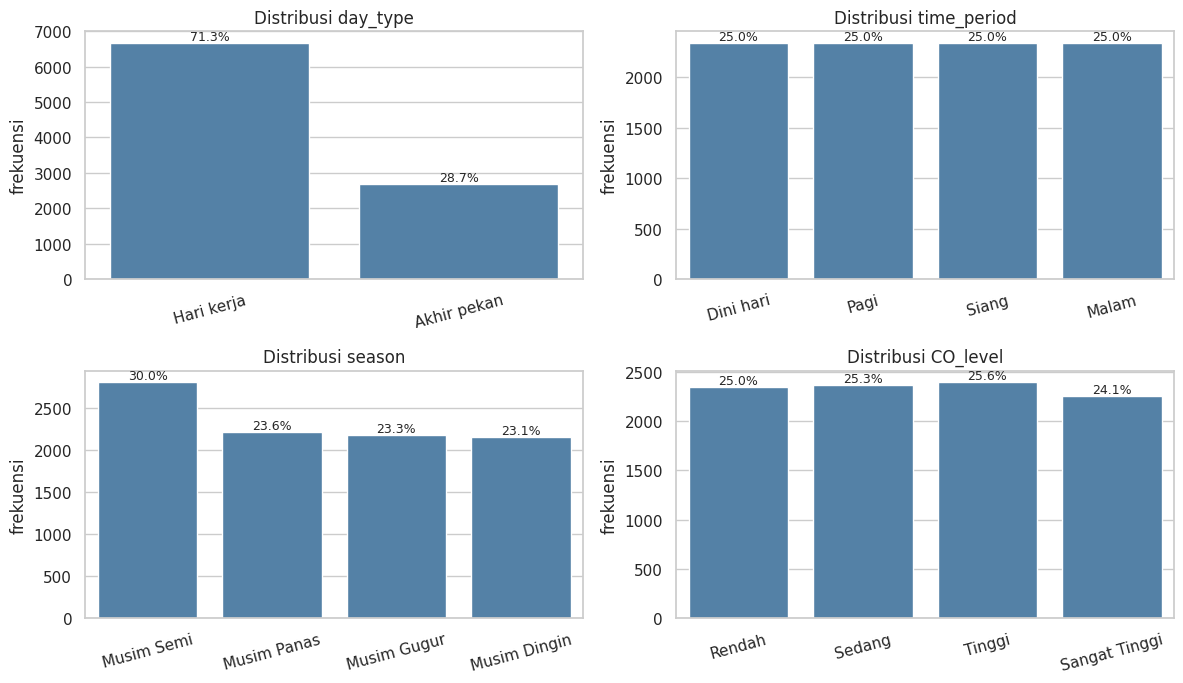


Ringkasan modus, kategori terjarang, dan class imbalance (kriteria: rasio > 1.5 atau kategori < 10%):


,Variabel,Kategori dominan (modus),% modus,Kategori paling jarang,% terjarang,Rasio terbesar:terkecil,Imbalance signifikan?
0,day_type,Hari kerja,71.27,Akhir pekan,28.73,2.48,Ya
1,time_period,Dini hari,25.01,Siang,24.98,1.00,Tidak
2,season,Musim Semi,29.98,Musim Dingin,23.08,1.30,Tidak
3,CO_level,Tinggi,25.57,Sangat Tinggi,24.06,1.06,Tidak


In [19]:
cat_vars = ["day_type", "time_period", "season", "CO_level"]
imb_rows = []

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, c in zip(axes.ravel(), cat_vars):
    tab = df_analytic[c].value_counts().sort_index().rename_axis(c).reset_index(name="frekuensi")
    tab["persentase"] = (tab["frekuensi"] / tab["frekuensi"].sum() * 100).round(2)
    print(f"\nTabel frekuensi: {c}")
    display(tab)
    tab.to_csv(f"{OUT}/frequency_{c}.csv", index=False)

    sns.barplot(data=tab, x=c, y="frekuensi", ax=ax, color="steelblue")
    for i, (f, p) in enumerate(zip(tab["frekuensi"], tab["persentase"])):
        ax.text(i, f, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Distribusi {c}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

    top = tab.loc[tab["frekuensi"].idxmax()]
    low = tab.loc[tab["frekuensi"].idxmin()]
    ratio = top["frekuensi"] / low["frekuensi"]
    imbalanced = (ratio > 1.5) or (low["persentase"] < 10)
    imb_rows.append([c, str(top[c]), top["persentase"], str(low[c]), low["persentase"],
                     round(ratio, 2), "Ya" if imbalanced else "Tidak"])
plt.tight_layout()
savefig("bar_kategorik")
plt.show()

imbalance_table = pd.DataFrame(imb_rows, columns=[
    "Variabel", "Kategori dominan (modus)", "% modus", "Kategori paling jarang", "% terjarang",
    "Rasio terbesar:terkecil", "Imbalance signifikan?"])
print("\nRingkasan modus, kategori terjarang, dan class imbalance (kriteria: rasio > 1.5 atau kategori < 10%):")
display(imbalance_table)
imbalance_table.to_csv(f"{OUT}/ringkasan_imbalance.csv", index=False)

**Interpretasi C.2**

- `time_period` dan `CO_level` hampir seimbang **karena cara pembentukannya** (jam dibagi rata dan kuartil membagi data sama banyak), jadi keseimbangannya bukan temuan substantif. `day_type` berimbang 5:2 sesuai kalender (71,27% hari kerja dan 28,73% akhir pekan, rasio 2,48), yang juga bukan ketidakseimbangan yang bermasalah.
- `season` adalah variabel yang paling informatif untuk menilai ketidakseimbangan, karena rentang pengamatan (Maret 2004 sampai awal April 2005) membuat Musim Semi tercatat dua kali sebagian (29,98%), sedangkan musim lain satu kali (23,08% sampai 23,60%), dengan rasio 1,30.
- **Dampak pada pemodelan:** bila kategori ini dipakai sebagai target klasifikasi, kelas minoritas akan kurang terwakili sehingga model cenderung bias ke kelas mayoritas. Mitigasinya adalah stratified split, pembobotan kelas, atau metrik selain akurasi (F1, recall per kelas).

## D.1 Numerik vs Numerik

## Scatter plot dan korelasi Pearson (D.1.1 dan D.1.2)
Empat pasang variabel yang diduga berhubungan: `CO` vs `NOx` (sama-sama emisi kendaraan), `C6H6` vs `CO`, `T` vs `RH`, dan `T` vs `AH`. Korelasi Pearson dilengkapi p-value dan Spearman (tahan terhadap outlier dan distribusi miring) sebagai pembanding.

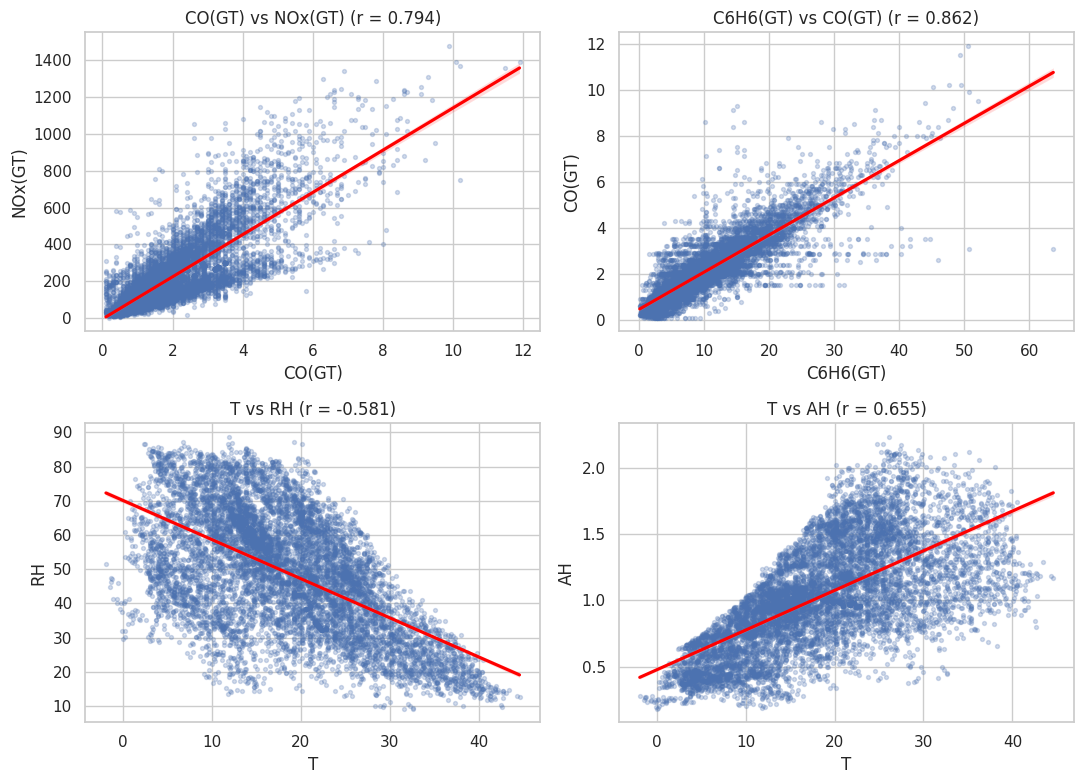

,Pasangan,Pearson r,p-value,Spearman rho
0,CO(GT) vs NOx(GT),0.7942,p < 0.001,0.7889
1,C6H6(GT) vs CO(GT),0.8621,p < 0.001,0.8803
2,T vs RH,-0.5811,p < 0.001,-0.5466
3,T vs AH,0.6548,p < 0.001,0.6974


In [20]:
pairs = [("CO(GT)", "NOx(GT)"), ("C6H6(GT)", "CO(GT)"), ("T", "RH"), ("T", "AH")]
pairs = [(x, y) for x, y in pairs if x in df_analytic.columns and y in df_analytic.columns]

corr_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (x, y) in zip(axes.ravel(), pairs):
    r, p = stats.pearsonr(df_analytic[x], df_analytic[y])
    rho, _ = stats.spearmanr(df_analytic[x], df_analytic[y])
    corr_rows.append([f"{x} vs {y}", round(r, 4), "p < 0.001" if p < 0.001 else f"{p:.4f}", round(rho, 4)])
    sns.regplot(data=df_analytic, x=x, y=y, ax=ax,
                scatter_kws={"alpha": 0.25, "s": 8}, line_kws={"color": "red"})
    ax.set_title(f"{x} vs {y} (r = {r:.3f})")
plt.tight_layout()
savefig("scatter_pairs")
plt.show()

pair_corr = pd.DataFrame(corr_rows, columns=["Pasangan", "Pearson r", "p-value", "Spearman rho"])
display(pair_corr)
pair_corr.to_csv(f"{OUT}/korelasi_pasangan.csv", index=False)

## Matriks korelasi, heatmap, korelasi tertinggi/terendah, multikolinearitas (VIF), dan korelasi ≠ kausalitas (D.1.3 sampai D.1.5)
Matriks korelasi seluruh variabel numerik divisualisasikan sebagai heatmap. Pasangan dengan korelasi tertinggi dan terendah diidentifikasi otomatis, multikolinearitas diperiksa lewat VIF (dihitung dari invers matriks korelasi; VIF > 10 dianggap tinggi), dan sebuah contoh dipakai untuk menunjukkan bahwa korelasi bukan kausalitas.

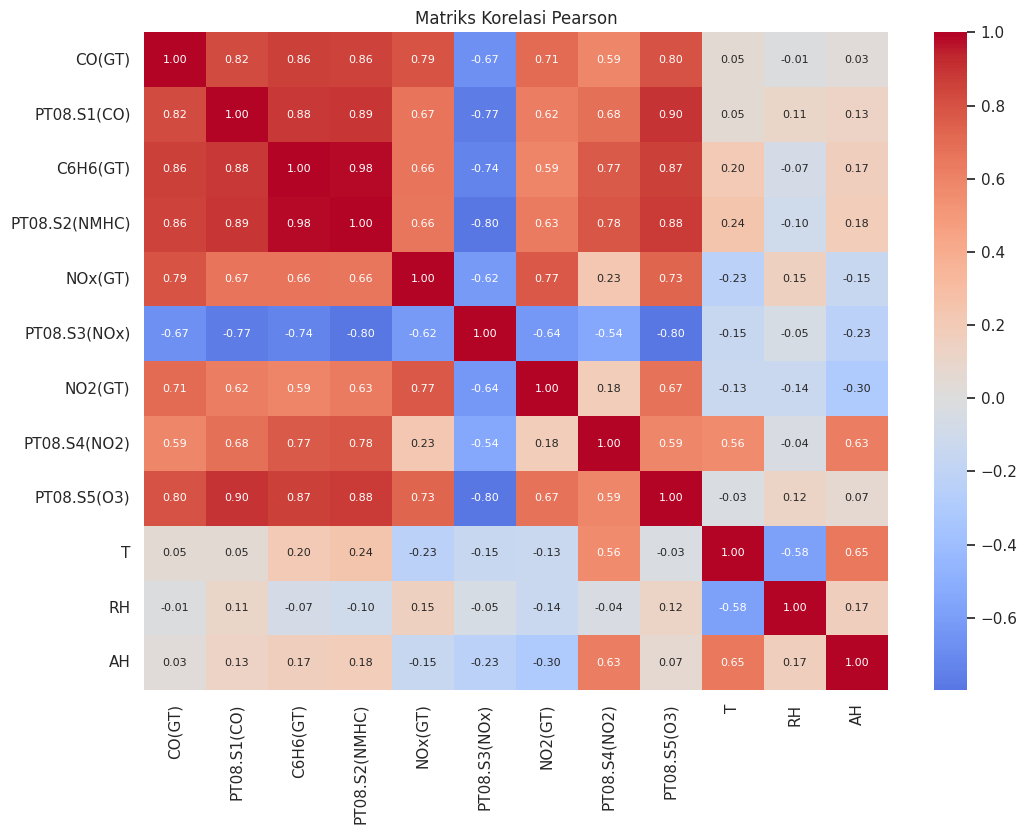

Korelasi positif TERTINGGI : C6H6(GT) vs PT08.S2(NMHC) (r = 0.982)
Korelasi negatif TERKUAT   : PT08.S2(NMHC) vs PT08.S3(NOx) (r = -0.798)
Korelasi TERLEMAH (~0)     : CO(GT) vs RH (r = -0.010)

10 pasangan dengan |r| terbesar:


,var1,var2,r,abs_r
0,C6H6(GT),PT08.S2(NMHC),0.982,0.982
1,PT08.S1(CO),PT08.S5(O3),0.900,0.900
2,PT08.S1(CO),PT08.S2(NMHC),0.894,0.894
3,PT08.S1(CO),C6H6(GT),0.885,0.885
4,PT08.S2(NMHC),PT08.S5(O3),0.880,0.880
5,C6H6(GT),PT08.S5(O3),0.866,0.866
6,CO(GT),C6H6(GT),0.862,0.862
7,CO(GT),PT08.S2(NMHC),0.856,0.856
8,CO(GT),PT08.S1(CO),0.824,0.824
9,PT08.S2(NMHC),PT08.S3(NOx),-0.798,0.798


Pasangan dengan |r| >= 0.90 (indikasi multikolinearitas):


,var1,var2,r,abs_r
0,C6H6(GT),PT08.S2(NMHC),0.982,0.982


,VIF
PT08.S2(NMHC),65.97
C6H6(GT),41.39
T,14.47
PT08.S4(NO2),13.73
AH,10.48
PT08.S5(O3),8.56
PT08.S1(CO),8.45
RH,8.20
CO(GT),7.10
NOx(GT),5.98


Variabel dengan VIF > 10: ['PT08.S2(NMHC)', 'C6H6(GT)', 'T', 'PT08.S4(NO2)', 'AH']

Contoh korelasi bukan kausalitas: CO(GT) vs NOx(GT) r = 0.794 (keseluruhan)
Korelasi CO-NOx per periode waktu:
time_period
Dini hari    0.767
Pagi         0.749
Siang        0.779
Malam        0.795


In [21]:
corr_cols = [c for c in analytic_meas if c in df_analytic.columns]
corr = df_analytic[corr_cols].corr(method="pearson")
corr.to_csv(f"{OUT}/matriks_korelasi.csv")

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Matriks Korelasi Pearson")
plt.tight_layout()
savefig("heatmap_korelasi")
plt.show()

# --- Pasangan tertinggi dan terendah
tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pair_list = tri.stack().reset_index()
pair_list.columns = ["var1", "var2", "r"]
pair_list["abs_r"] = pair_list["r"].abs()

hi = pair_list.loc[pair_list["r"].idxmax()]
neg = pair_list.loc[pair_list["r"].idxmin()]
zero = pair_list.loc[pair_list["abs_r"].idxmin()]
print("Korelasi positif TERTINGGI :", hi["var1"], "vs", hi["var2"], f"(r = {hi['r']:.3f})")
print("Korelasi negatif TERKUAT   :", neg["var1"], "vs", neg["var2"], f"(r = {neg['r']:.3f})")
print("Korelasi TERLEMAH (~0)     :", zero["var1"], "vs", zero["var2"], f"(r = {zero['r']:.3f})")
print("\n10 pasangan dengan |r| terbesar:")
display(pair_list.sort_values("abs_r", ascending=False).head(10).round(3).reset_index(drop=True))

# --- Multikolinearitas
print("Pasangan dengan |r| >= 0.90 (indikasi multikolinearitas):")
high_pairs = pair_list[pair_list["abs_r"] >= 0.90].sort_values("abs_r", ascending=False)
display(high_pairs.round(3).reset_index(drop=True) if len(high_pairs) else "Tidak ada")

try:
    vif = pd.Series(np.diag(np.linalg.inv(corr.values)), index=corr.index, name="VIF").sort_values(ascending=False)
    display(vif.round(2).to_frame())
    print("Variabel dengan VIF > 10:", vif[vif > 10].index.tolist() or "tidak ada")
    vif.to_csv(f"{OUT}/vif.csv")
except np.linalg.LinAlgError:
    print("Matriks korelasi singular: multikolinearitas sempurna terdeteksi.")

# --- Contoh korelasi != kausalitas
if {"CO(GT)", "NOx(GT)"} <= set(df_analytic.columns):
    r_all = df_analytic["CO(GT)"].corr(df_analytic["NOx(GT)"])
    by_period = df_analytic.groupby("time_period", observed=True)[["CO(GT)", "NOx(GT)"]].apply(
        lambda g: g["CO(GT)"].corr(g["NOx(GT)"]))
    print(f"\nContoh korelasi bukan kausalitas: CO(GT) vs NOx(GT) r = {r_all:.3f} (keseluruhan)")
    print("Korelasi CO-NOx per periode waktu:")
    print(by_period.round(3).to_string())

**Interpretasi D.1**

- Korelasi tertinggi terjadi antara `C6H6(GT)` dan `PT08.S2(NMHC)` (r = 0,982) karena sensor PT08.S2 memang dirancang untuk merespons hidrokarbon aromatik, dan juga antara beberapa sensor PT08 dengan analyzer referensinya. Korelasi terlemah (mendekati 0) terjadi antara `CO(GT)` dan `RH` (r = −0,010), sedangkan korelasi negatif terkuat antara `PT08.S2(NMHC)` dan `PT08.S3(NOx)` (r = −0,798).
- **Multikolinearitas:** satu pasangan dengan |r| ≥ 0,9 (`C6H6(GT)` dan `PT08.S2(NMHC)`) dan lima variabel ber-VIF > 10 (PT08.S2(NMHC) 65,97; C6H6(GT) 41,39; T 14,47; PT08.S4(NO2) 13,73; AH 10,48) menandakan informasi yang berulang. Jika variabel-variabel ini dimasukkan ke regresi, koefisien menjadi tidak stabil; pada PCA, redundansi ini justru yang membuat sedikit komponen sudah menjelaskan banyak varians.
-  **Korelasi ≠ kausalitas:** `CO(GT)` dan `NOx(GT)` berkorelasi kuat (r ≈ 0,79), tetapi hal ini tidak berarti CO menyebabkan NOx atau sebaliknya. Keduanya sama-sama berasal dari emisi kendaraan, sehingga naik-turun bersamaan mengikuti kepadatan lalu lintas (faktor ketiga atau *confounder*). Korelasinya tetap kuat di semua periode waktu (sekitar 0,75–0,80), yang konsisten dengan sumber emisi bersama, namun korelasi saja tidak cukup untuk membuktikan hubungan sebab-akibat.

## D.2 Kategorik vs Kategorik

## Tabulasi silang dan uji Chi-Square (D.2)
Tiga pasang variabel diuji: `time_period` × `CO_level`, `day_type` × `CO_level`, dan `season` × `CO_level`. Untuk tiap pasang ditampilkan tabulasi silang (frekuensi dan persentase baris), uji Chi-Square, ukuran efek Cramér's V, pengecekan frekuensi harapan, dan kesimpulan otomatis pada α = 0,05.


--- Tabulasi silang: time_period x CO_level ---


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
time_period,,,,
Dini hari,1417,636,219,68
Pagi,546,541,525,728
Siang,260,541,1033,503
Malam,120,652,616,952


Persentase baris (%):


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
time_period,,,,
Dini hari,60.6,27.2,9.4,2.9
Pagi,23.3,23.1,22.4,31.1
Siang,11.1,23.1,44.2,21.5
Malam,5.1,27.9,26.3,40.7


Chi-Square = 3076.54, dof = 9, p < 0.001, Cramér's V = 0.331 (sedang)
Sel dengan frekuensi harapan < 5: 0 dari 16 (asumsi terpenuhi)
KESIMPULAN: ada hubungan signifikan antara time_period dan CO_level (p < 0.05), kekuatan sedang.


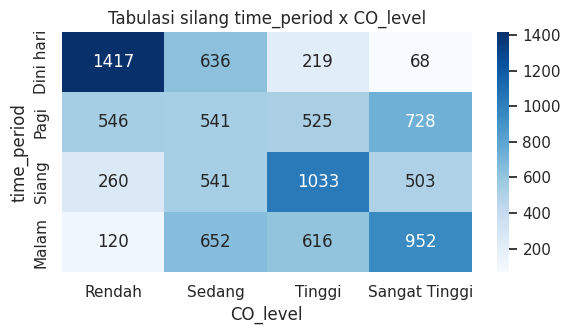


--- Tabulasi silang: day_type x CO_level ---


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
day_type,,,,
Hari kerja,1492,1531,1743,1903
Akhir pekan,851,839,650,348


Persentase baris (%):


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
day_type,,,,
Hari kerja,22.4,23.0,26.1,28.5
Akhir pekan,31.7,31.2,24.2,12.9


Chi-Square = 313.93, dof = 3, p < 0.001, Cramér's V = 0.183 (lemah)
Sel dengan frekuensi harapan < 5: 0 dari 8 (asumsi terpenuhi)
KESIMPULAN: ada hubungan signifikan antara day_type dan CO_level (p < 0.05), kekuatan lemah.


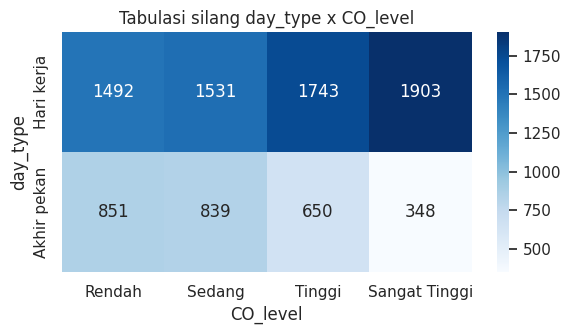


--- Tabulasi silang: season x CO_level ---


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
season,,,,
Musim Semi,726,700,740,639
Musim Panas,668,640,584,316
Musim Gugur,470,472,565,677
Musim Dingin,479,558,504,619


Persentase baris (%):


CO_level,Rendah,Sedang,Tinggi,Sangat Tinggi
season,,,,
Musim Semi,25.9,25.0,26.4,22.8
Musim Panas,30.3,29.0,26.4,14.3
Musim Gugur,21.5,21.6,25.9,31.0
Musim Dingin,22.2,25.8,23.3,28.7


Chi-Square = 224.09, dof = 9, p < 0.001, Cramér's V = 0.089 (diabaikan)
Sel dengan frekuensi harapan < 5: 0 dari 16 (asumsi terpenuhi)
KESIMPULAN: ada hubungan signifikan antara season dan CO_level (p < 0.05), kekuatan diabaikan.


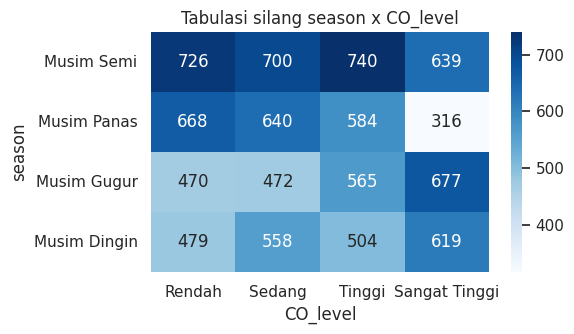

,Pasangan,Chi-Square,dof,p-value,Cramér's V,Kekuatan,Keputusan (a=0.05)
0,time_period x CO_level,3076.54,9,p < 0.001,0.331,sedang,Signifikan
1,day_type x CO_level,313.93,3,p < 0.001,0.183,lemah,Signifikan
2,season x CO_level,224.09,9,p < 0.001,0.089,diabaikan,Signifikan


In [22]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / min(k - 1, r - 1))

def v_strength(v):
    return "diabaikan" if v < 0.1 else "lemah" if v < 0.3 else "sedang" if v < 0.5 else "kuat"

cat_pairs = [("time_period", "CO_level"), ("day_type", "CO_level"), ("season", "CO_level")]
chi_rows = []

for a, b in cat_pairs:
    ct = pd.crosstab(df_analytic[a], df_analytic[b])
    print(f"\n--- Tabulasi silang: {a} x {b} ---")
    display(ct)
    print("Persentase baris (%):")
    display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

    chi2, p, dof, expected = stats.chi2_contingency(ct)
    v = cramers_v(ct)
    n_low = int((expected < 5).sum())
    p_txt = "p < 0.001" if p < 0.001 else f"p = {p:.4f}"
    sig = p < 0.05
    print(f"Chi-Square = {chi2:.2f}, dof = {dof}, {p_txt}, Cramér's V = {v:.3f} ({v_strength(v)})")
    print(f"Sel dengan frekuensi harapan < 5: {n_low} dari {expected.size} "
          f"({'asumsi terpenuhi' if n_low == 0 else 'asumsi dilanggar'})")
    print("KESIMPULAN:", f"ada hubungan signifikan antara {a} dan {b} (p < 0.05), kekuatan {v_strength(v)}."
          if sig else f"tidak ada bukti hubungan signifikan antara {a} dan {b}.")
    chi_rows.append([f"{a} x {b}", round(chi2, 2), dof, p_txt, round(v, 3), v_strength(v), "Signifikan" if sig else "Tidak signifikan"])

    plt.figure(figsize=(6, 3.5))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Tabulasi silang {a} x {b}")
    plt.tight_layout()
    savefig(f"crosstab_{a}_{b}")
    plt.show()

chi_table = pd.DataFrame(chi_rows, columns=["Pasangan", "Chi-Square", "dof", "p-value", "Cramér's V", "Kekuatan", "Keputusan (a=0.05)"])
display(chi_table)
chi_table.to_csv(f"{OUT}/chi_square.csv", index=False)

**Interpretasi D.2**

- Ketiga uji menghasilkan p < 0,05: tingkat CO **berhubungan** dengan periode hari, jenis hari, dan musim. Secara kontekstual, kategori CO Sangat Tinggi mencapai 40,7% pada malam hari (dini hari hanya 2,9%) dan 28,5% pada hari kerja (akhir pekan 12,9%), sedangkan dini hari (60,6% Rendah) dan akhir pekan lebih banyak berada pada kategori rendah. Hal ini sejalan dengan aktivitas lalu lintas.
- **Ukuran efek penting:** dengan n > 9.000, p-value akan hampir selalu sangat kecil. Cramér's V menunjukkan bahwa hubungan `time_period` × `CO_level` (V = 0,331; sedang) lebih kuat daripada `day_type` × `CO_level` (V = 0,183; lemah) dan `season` × `CO_level` (V = 0,089; diabaikan), sehingga jam dalam sehari lebih menentukan tingkat CO dibanding jenis hari.
- **Caveat:** data per jam berautokorelasi sehingga asumsi independensi uji Chi-Square tidak terpenuhi sepenuhnya. Hasilnya dipahami sebagai indikasi hubungan, bukan bukti kausal, dan p-value cenderung terlalu optimistis.

## D.3 Numerik vs Kategorik

## Boxplot per kelompok, ANOVA, uji t, dan uji lanjutan (D.3)
Dua analisis: (1) `NO2(GT)` menurut `time_period` (4 kelompok) memakai **ANOVA**, dilengkapi uji Levene (homogenitas varians), Kruskal-Wallis (alternatif nonparametrik), eta-squared (ukuran efek), dan uji lanjut Tukey; (2) `CO(GT)` menurut `day_type` (2 kelompok) memakai **uji t Welch** dan Cohen's d.

,count,mean,median,std
time_period,,,,
Dini hari,2340,75.51,69.5,33.77
Pagi,2340,113.26,111.0,45.63
Siang,2337,122.47,119.0,40.51
Malam,2340,131.88,125.0,42.82


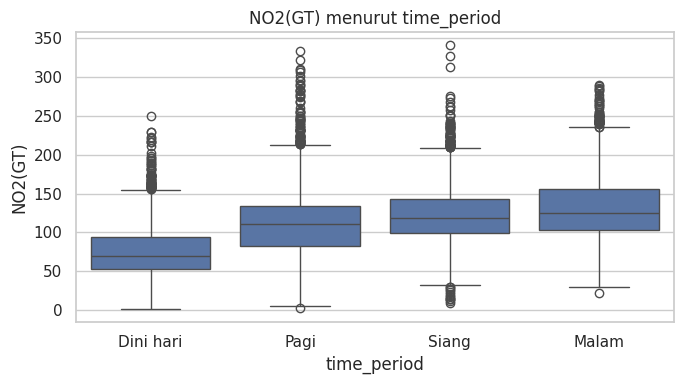

Levene (homogenitas varians): stat = 51.687, p < 0.001 -> varians TIDAK homogen
ANOVA satu arah             : F = 853.15, p < 0.001, eta^2 = 0.215
Kruskal-Wallis              : H = 2315.26, p < 0.001
KESIMPULAN: rata-rata NO2 berbeda signifikan antarperiode waktu (p < 0.05).

Uji lanjut Tukey HSD:


,Pasangan kelompok,Selisih mean,p-value,Keputusan
0,Dini hari vs Pagi,-37.75,p < 0.001,Beda signifikan
1,Dini hari vs Siang,-46.95,p < 0.001,Beda signifikan
2,Dini hari vs Malam,-56.37,p < 0.001,Beda signifikan
3,Pagi vs Siang,-9.21,p < 0.001,Beda signifikan
4,Pagi vs Malam,-18.62,p < 0.001,Beda signifikan
5,Siang vs Malam,-9.41,p < 0.001,Beda signifikan


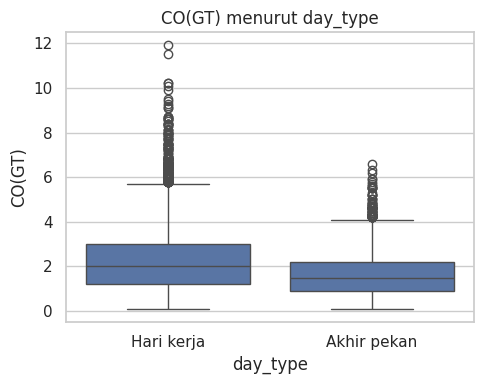


Rata-rata CO(GT): Hari kerja = 2.250, Akhir pekan = 1.684
Levene: p < 0.001 -> uji t Welch dipakai (tidak mengasumsikan varians sama)
Uji t Welch : t = 21.44, p < 0.001, Cohen's d = 0.450
Mann-Whitney: U = 10963374, p < 0.001
KESIMPULAN: rata-rata CO berbeda signifikan antara hari kerja dan akhir pekan.


In [23]:
# ============ (1) NO2(GT) ~ time_period : ANOVA ============
num_var, cat_var = "NO2(GT)", "time_period"
summary = df_analytic.groupby(cat_var, observed=True)[num_var].agg(["count", "mean", "median", "std"]).round(2)
display(summary)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df_analytic, x=cat_var, y=num_var)
plt.title(f"{num_var} menurut {cat_var}")
plt.tight_layout()
savefig(f"boxplot_{num_var}_{cat_var}")
plt.show()

grouped = [(k, g[num_var].values) for k, g in df_analytic.groupby(cat_var, observed=True)]
names = [k for k, _ in grouped]
groups = [v for _, v in grouped]

lev_stat, lev_p = stats.levene(*groups)
f_stat, f_p = stats.f_oneway(*groups)
h_stat, h_p = stats.kruskal(*groups)

grand = np.concatenate(groups).mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = sum(((g - grand) ** 2).sum() for g in groups)
eta2 = ss_between / ss_total

fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.4f}"
print(f"Levene (homogenitas varians): stat = {lev_stat:.3f}, {fmt_p(lev_p)} "
      f"-> varians {'TIDAK homogen' if lev_p < 0.05 else 'homogen'}")
print(f"ANOVA satu arah             : F = {f_stat:.2f}, {fmt_p(f_p)}, eta^2 = {eta2:.3f}")
print(f"Kruskal-Wallis              : H = {h_stat:.2f}, {fmt_p(h_p)}")
print("KESIMPULAN:", "rata-rata NO2 berbeda signifikan antarperiode waktu (p < 0.05)."
      if f_p < 0.05 else "tidak ada perbedaan rata-rata NO2 yang signifikan antarperiode waktu.")

try:
    tk = stats.tukey_hsd(*groups)
    tuk_rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            tuk_rows.append([f"{names[i]} vs {names[j]}", round(groups[i].mean() - groups[j].mean(), 2),
                             fmt_p(tk.pvalue[i, j]), "Beda signifikan" if tk.pvalue[i, j] < 0.05 else "Tidak beda"])
    print("\nUji lanjut Tukey HSD:")
    display(pd.DataFrame(tuk_rows, columns=["Pasangan kelompok", "Selisih mean", "p-value", "Keputusan"]))
except AttributeError:
    print("\n(tukey_hsd tidak tersedia pada versi SciPy ini; perbarui SciPy untuk uji lanjut.)")

# ============ (2) CO(GT) ~ day_type : uji t Welch ============
num2, cat2 = "CO(GT)", "day_type"
g1 = df_analytic.loc[df_analytic[cat2] == "Hari kerja", num2].values
g2 = df_analytic.loc[df_analytic[cat2] == "Akhir pekan", num2].values

plt.figure(figsize=(5, 4))
sns.boxplot(data=df_analytic, x=cat2, y=num2)
plt.title(f"{num2} menurut {cat2}")
plt.tight_layout()
savefig(f"boxplot_{num2}_{cat2}")
plt.show()

lev2_stat, lev2_p = stats.levene(g1, g2)
t_stat, t_p = stats.ttest_ind(g1, g2, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(g1, g2, alternative="two-sided")
pooled = np.sqrt((g1.std(ddof=1) ** 2 + g2.std(ddof=1) ** 2) / 2)
cohen_d = (g1.mean() - g2.mean()) / pooled

print(f"\nRata-rata {num2}: Hari kerja = {g1.mean():.3f}, Akhir pekan = {g2.mean():.3f}")
print(f"Levene: {fmt_p(lev2_p)} -> uji t Welch dipakai (tidak mengasumsikan varians sama)")
print(f"Uji t Welch : t = {t_stat:.2f}, {fmt_p(t_p)}, Cohen's d = {cohen_d:.3f}")
print(f"Mann-Whitney: U = {u_stat:.0f}, {fmt_p(u_p)}")
print("KESIMPULAN:", "rata-rata CO berbeda signifikan antara hari kerja dan akhir pekan."
      if t_p < 0.05 else "tidak ada perbedaan rata-rata CO yang signifikan antara hari kerja dan akhir pekan.")

**Interpretasi D.3**

- **NO2 menurut periode:** median NO2 paling rendah pada dini hari (69,5) dan meningkat pada pagi (111,0), siang (119,0), sampai malam (125,0). ANOVA (dan Kruskal-Wallis sebagai penguat, karena uji Levene menandakan varians tidak sepenuhnya homogen) menyatakan perbedaan rata-rata signifikan (F = 853,15; H = 2.315,26; p < 0,001). Uji Tukey menunjukkan seluruh enam pasangan periode berbeda signifikan, dan eta-squared 0,215 berarti sekitar 21,5% variasi NO2 dijelaskan oleh periode waktu.
- **CO menurut jenis hari:** uji t Welch membandingkan rata-rata CO pada hari kerja dan akhir pekan. Rata-rata CO hari kerja 2,250 mg/m3 dan akhir pekan 1,684 mg/m3 (t = 21,44; p < 0,001; Cohen's d = 0,450, efek sedang), dikuatkan Mann-Whitney (p < 0,001). Hasil ini konsisten dengan dugaan bahwa lalu lintas hari kerja lebih padat.
- Seperti pada D.2, observasi per jam berautokorelasi sehingga p-value perlu dibaca bersama ukuran efek.

## E.1 Principal Component Analysis (PCA)
**Mengapa standardisasi wajib.** PCA mencari arah dengan varians terbesar. Variabel berskala besar (NOx dalam ratusan ppb) akan mendominasi komponen utama hanya karena satuannya, bukan karena informasinya. Standardisasi (mean = 0, std = 1) membuat setiap variabel berkontribusi setara, sehingga PCA bekerja pada matriks korelasi.

##  PCA: standardisasi, explained variance, scree plot, dan jumlah komponen optimal (E.1.1 sampai E.1.4)
Tujuh variabel numerik (`CO`, `C6H6`, `NOx`, `NO2`, `T`, `RH`, `AH`, versi winsorized) distandardisasi dengan `StandardScaler`, lalu PCA dihitung. Jumlah komponen optimal ditentukan dengan aturan 80% varians kumulatif (dengan kriteria Kaiser sebagai pembanding).

Fitur PCA: ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH', 'AH']

Bukti standardisasi (mean ~ 0, std = 1):


,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
mean,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,PC,eigenvalue,explained_variance_ratio,cumulative
0,PC1,3.2459,0.4636,0.4636
1,PC2,1.9362,0.2766,0.7402
2,PC3,1.2421,0.1774,0.9176
3,PC4,0.2869,0.0410,0.9586
4,PC5,0.1473,0.0210,0.9797
5,PC6,0.1054,0.0151,0.9947
6,PC7,0.0370,0.0053,1.0000


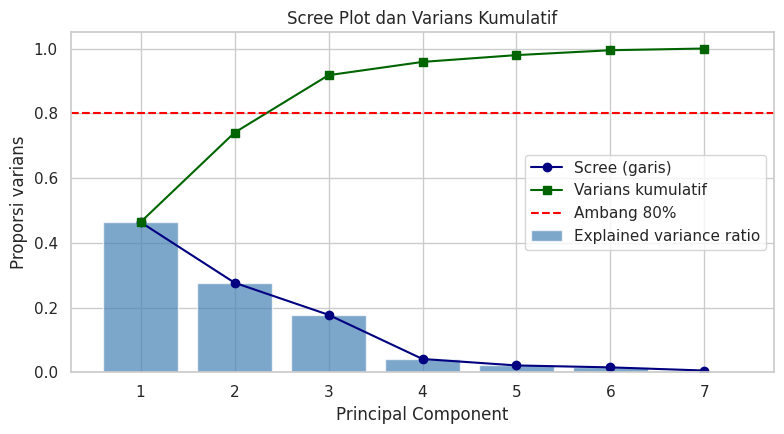

Jumlah komponen untuk >= 80% varians kumulatif: 3 (kumulatif = 91.8%)
Pembanding, kriteria Kaiser (eigenvalue > 1)     : 3 komponen


In [24]:
print("Fitur PCA:", pca_features)
X_pca = df_analytic[[f"{c}_winsor" for c in pca_features]]
X_pca.columns = pca_features

# Standardisasi (wajib)
scaler_pca = StandardScaler()
X_z = scaler_pca.fit_transform(X_pca)
print("\nBukti standardisasi (mean ~ 0, std = 1):")
display(pd.DataFrame(X_z, columns=pca_features).describe().loc[["mean", "std"]].round(3))

pca = PCA(random_state=RANDOM_STATE)
scores = pca.fit_transform(X_z)
evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

pca_table = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(evr))],
    "eigenvalue": pca.explained_variance_,
    "explained_variance_ratio": evr,
    "cumulative": cum_evr,
})
display(pca_table.round(4))
pca_table.to_csv(f"{OUT}/pca_variance.csv", index=False)

# Scree plot
pcs = np.arange(1, len(evr) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pcs, evr, color="steelblue", alpha=0.7, label="Explained variance ratio")
ax.plot(pcs, evr, marker="o", color="navy", label="Scree (garis)")
ax.plot(pcs, cum_evr, marker="s", color="darkgreen", label="Varians kumulatif")
ax.axhline(0.8, color="red", linestyle="--", label="Ambang 80%")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Proporsi varians")
ax.set_xticks(pcs)
ax.set_title("Scree Plot dan Varians Kumulatif")
ax.legend(loc="center right")
plt.tight_layout()
savefig("pca_scree")
plt.show()

n_components_80 = int(np.argmax(cum_evr >= 0.8) + 1)
n_kaiser = int((pca.explained_variance_ > 1).sum())
print(f"Jumlah komponen untuk >= 80% varians kumulatif: {n_components_80} "
      f"(kumulatif = {cum_evr[n_components_80-1]*100:.1f}%)")
print(f"Pembanding, kriteria Kaiser (eigenvalue > 1)     : {n_kaiser} komponen")

## PCA: loading dan variabel yang paling berkontribusi (E.1.5)
Loading ditampilkan sebagai tabel dan heatmap. Kontribusi variabel pada tiap komponen dihitung sebagai loading kuadrat dikali 100 (jumlah per komponen = 100%).

Loading (arah dan bobot variabel pada tiap komponen):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
CO(GT),0.518,0.108,0.093,-0.327,0.032,0.776,-0.005
C6H6(GT),0.478,0.235,0.123,-0.559,-0.186,-0.595,-0.021
NOx(GT),0.506,-0.135,0.097,0.370,0.733,-0.204,0.023
NO2(GT),0.490,-0.085,-0.217,0.568,-0.618,-0.025,-0.008
T,-0.038,0.703,-0.091,0.180,0.061,0.017,0.677
RH,-0.016,-0.375,0.757,0.042,-0.195,0.000,0.496
AH,-0.072,0.522,0.581,0.295,-0.055,0.028,-0.542


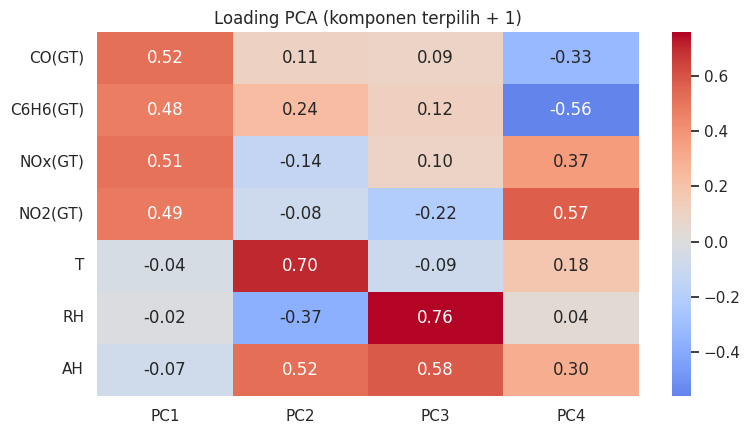


=== VARIABEL PALING BERKONTRIBUSI PADA KOMPONEN TERPILIH ===
PC1 (varians 46.4%): CO(GT) (26.9%, loading +0.52), NOx(GT) (25.6%, loading +0.51), NO2(GT) (24.0%, loading +0.49)
PC2 (varians 27.7%): T (49.5%, loading +0.70), AH (27.2%, loading +0.52), RH (14.0%, loading -0.37)
PC3 (varians 17.7%): RH (57.4%, loading +0.76), AH (33.8%, loading +0.58), NO2(GT) (4.7%, loading -0.22)


In [25]:
pc_names = [f"PC{i+1}" for i in range(len(pca_features))]
loadings = pd.DataFrame(pca.components_.T, index=pca_features, columns=pc_names)
contrib = (loadings ** 2) * 100

print("Loading (arah dan bobot variabel pada tiap komponen):")
display(loadings.round(3))
loadings.to_csv(f"{OUT}/pca_loadings.csv")

plt.figure(figsize=(8, 4.5))
sns.heatmap(loadings.iloc[:, :n_components_80 + 1], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loading PCA (komponen terpilih + 1)")
plt.tight_layout()
savefig("pca_loadings_heatmap")
plt.show()

print("\n=== VARIABEL PALING BERKONTRIBUSI PADA KOMPONEN TERPILIH ===")
for pc in pc_names[:n_components_80]:
    top = contrib[pc].sort_values(ascending=False).head(3)
    desc = ", ".join(f"{v} ({contrib.loc[v, pc]:.1f}%, loading {loadings.loc[v, pc]:+.2f})" for v in top.index)
    print(f"{pc} (varians {evr[pc_names.index(pc)]*100:.1f}%): {desc}")

# Skor PC untuk dipakai pada visualisasi cluster
pca_scores = pd.DataFrame(scores[:, :n_components_80], columns=pc_names[:n_components_80])
pca_scores.to_csv(f"{OUT}/pca_scores.csv", index=False)

**Interpretasi E.1**

- Tiga komponen pertama menjelaskan 91,8% varians kumulatif (melewati ambang 80%; kriteria Kaiser juga memberi 3 komponen), sehingga tujuh variabel dapat diringkas menjadi tiga dimensi dengan kehilangan informasi yang kecil. Ini sejalan dengan temuan D.1 bahwa banyak variabel saling berkorelasi.
- **PC1 (≈46,4%)**: didominasi `CO`, `C6H6`, `NOx`, dan `NO2` dengan loading sama arah. PC1 dapat dibaca sebagai **dimensi tingkat pencemaran dari lalu lintas**, nilai tinggi berarti semua polutan tinggi bersamaan.
- **PC2 (≈28%)**: didominasi `T` dan `AH` (loading positif) serta `RH` (loading negatif), yaitu **dimensi suhu dan kelembapan absolut**. Skor tinggi berarti udara hangat dengan kandungan uap air absolut tinggi tetapi kelembapan relatif rendah, karena udara hangat dapat menampung lebih banyak uap air.
- **PC3 (≈18%)**: didominasi `RH` dan `AH` yang bergerak searah, sedangkan `T` hampir tidak berperan (loading −0,09). Komponen ini menangkap **variasi kelembapan udara yang terpisah dari suhu**.
- Polutan dan variabel cuaca terpisah pada komponen yang berbeda: pada PC1, loading `T`, `RH`, dan `AH` mendekati nol, sedangkan pada PC2 loading `CO`, `NOx`, dan `NO2` kecil. Artinya, variasi tingkat pencemaran pada dataset ini sebagian besar tidak searah dengan variasi cuaca.

## E.2 K-Means Clustering

##  K-Means: Elbow Method dan Silhouette Score untuk memilih k (E.2.1 dan E.2.2)
K-Means dijalankan pada data tersandardisasi untuk k = 2 sampai 10. Titik siku (*elbow*) dicari otomatis dengan metode jarak maksimum ke garis penghubung ujung kurva, dan Silhouette dihitung untuk setiap k. Aturan pemilihan k diterapkan secara eksplisit: bila silhouette pada k siku tidak jauh di bawah silhouette maksimum (selisih ≤ 0,10), k siku dipilih karena memberi segmentasi lebih kaya daripada pemisahan dua kelompok sederhana; bila tidak, k dengan silhouette tertinggi dipilih. Anda dapat memaksa nilai k lewat `K_OVERRIDE`.

,k,inertia,silhouette
0,2,44974.1554,0.3031
1,3,35262.2208,0.2587
2,4,29812.0399,0.2448
3,5,26700.8469,0.2265
4,6,24094.6369,0.2272
5,7,22103.4979,0.2345
6,8,20635.5821,0.2248
7,9,19466.1326,0.2242
8,10,18386.4864,0.2236


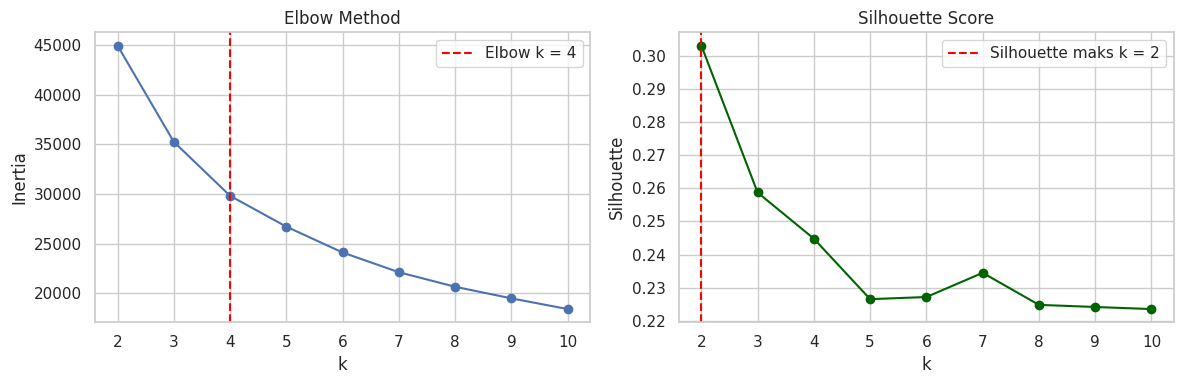

k menurut Elbow       : 4  (silhouette = 0.245)
k menurut Silhouette  : 2  (silhouette = 0.303)
k FINAL = 4  -> k siku dipilih (silhouette-nya hanya sedikit di bawah maksimum)


In [26]:
K_OVERRIDE = None          # isi mis. 3 atau 4 untuk memaksa jumlah cluster
k_features = pca_features
X_km_z = X_z               # data winsorized + tersandardisasi (sama dengan PCA)

k_range = list(range(2, 11))
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lab = km.fit_predict(X_km_z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_km_z, lab))

eval_k = pd.DataFrame({"k": k_range, "inertia": inertias, "silhouette": silhouettes})
display(eval_k.round(4))
eval_k.to_csv(f"{OUT}/kmeans_evaluation.csv", index=False)

def find_elbow(ks, vals):
    x = np.array(ks, float)
    y = np.array(vals, float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    dist = (1 - xn - yn) / np.sqrt(2)      # jarak ke garis dari (0,1) ke (1,0)
    return int(x[np.argmax(dist)])

k_elbow = find_elbow(k_range, inertias)
k_sil = int(eval_k.loc[eval_k["silhouette"].idxmax(), "k"])
sil_max = eval_k["silhouette"].max()
sil_at_elbow = float(eval_k.loc[eval_k["k"] == k_elbow, "silhouette"].iloc[0])

if K_OVERRIDE is not None:
    best_k, reason = int(K_OVERRIDE), "ditetapkan manual (K_OVERRIDE)"
elif sil_max - sil_at_elbow <= 0.10:
    best_k, reason = k_elbow, "k siku dipilih (silhouette-nya hanya sedikit di bawah maksimum)"
else:
    best_k, reason = k_sil, "k dengan silhouette tertinggi dipilih"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, marker="o")
axes[0].axvline(k_elbow, color="red", linestyle="--", label=f"Elbow k = {k_elbow}")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].legend()
axes[1].plot(k_range, silhouettes, marker="o", color="darkgreen")
axes[1].axvline(k_sil, color="red", linestyle="--", label=f"Silhouette maks k = {k_sil}")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].legend()
plt.tight_layout()
savefig("kmeans_elbow_silhouette")
plt.show()

print(f"k menurut Elbow       : {k_elbow}  (silhouette = {sil_at_elbow:.3f})")
print(f"k menurut Silhouette  : {k_sil}  (silhouette = {sil_max:.3f})")
print(f"k FINAL = {best_k}  -> {reason}")

## K-Means final, profil cluster, dan pemberian nama cluster (E.2.3 dan E.2.4)
K-Means dijalankan dengan k final. Profil tiap cluster (rata-rata dan median variabel asli) ditampilkan. Nama cluster dibuat otomatis dari dua hal: **tingkat polusi** (rata-rata z-score `CO`, `C6H6`, `NOx`, `NO2`, diurutkan dari terendah ke tertinggi) dan **kondisi suhu** (z-score `T`).

k = 4, silhouette final = 0.245

Profil cluster: RATA-RATA variabel per cluster


,n,persen,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
cluster,,,,,,,,,
0,2466,26.4,2.14,11.69,168.98,112.06,28.38,32.74,1.21
1,2693,28.8,1.00,4.75,95.89,65.46,17.74,58.94,1.20
2,1868,20.0,4.11,20.17,529.82,161.59,16.08,54.71,1.01
3,2330,24.9,1.67,6.37,223.43,121.04,10.11,50.82,0.64


Profil cluster: MEDIAN variabel per cluster


,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
cluster,,,,,,,
0,2.1,11.2,165.0,115.5,27.7,31.8,1.17
1,0.9,4.1,79.0,65.0,17.5,59.5,1.13
2,3.8,18.8,496.0,156.0,16.0,55.4,0.98
3,1.6,6.2,212.0,118.5,9.9,50.4,0.61


,cluster,nama_cluster,indeks_polusi_z,z_suhu,n
0,1,Polusi Rendah (suhu sedang),-0.84,-0.07,2693
1,3,Polusi Sedang (suhu dingin),-0.14,-0.94,2330
2,0,Polusi Sedang (suhu hangat),0.01,1.16,2466
3,2,Polusi Sangat Tinggi (suhu sedang),1.38,-0.26,1868


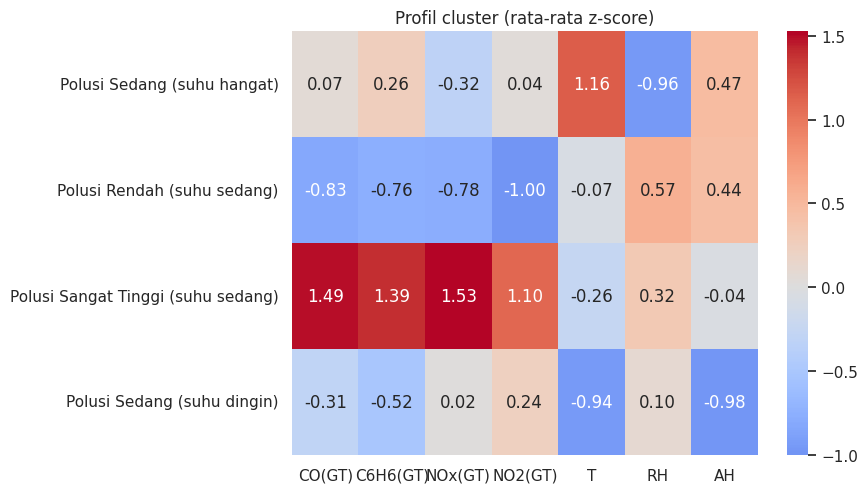

In [27]:
km_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df_analytic["cluster"] = km_final.fit_predict(X_km_z)
sil_final = silhouette_score(X_km_z, df_analytic["cluster"])
print(f"k = {best_k}, silhouette final = {sil_final:.3f}")

# Profil cluster pada satuan asli
counts = df_analytic["cluster"].value_counts().sort_index()
profile_mean = df_analytic.groupby("cluster")[k_features].mean()
profile_median = df_analytic.groupby("cluster")[k_features].median()
profile_mean.insert(0, "n", counts)
profile_mean.insert(1, "persen", (counts / counts.sum() * 100).round(1))
print("\nProfil cluster: RATA-RATA variabel per cluster")
display(profile_mean.round(2))
print("Profil cluster: MEDIAN variabel per cluster")
display(profile_median.round(2))
profile_mean.to_csv(f"{OUT}/cluster_profile_mean.csv")
profile_median.to_csv(f"{OUT}/cluster_profile_median.csv")

# Penamaan bermakna: ambang ABSOLUT pada indeks polusi (rata-rata z-score CO, C6H6, NOx, NO2)
z_df = pd.DataFrame(X_km_z, columns=k_features)
z_df["cluster"] = df_analytic["cluster"].values
z_prof = z_df.groupby("cluster").mean()

pol_cols = [c for c in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"] if c in k_features]
pol_idx = z_prof[pol_cols].mean(axis=1).sort_values()          # rendah -> tinggi

def pol_level(z):
    if z < -0.5:
        return "Rendah"
    elif z < 0.5:
        return "Sedang"
    elif z < 1.0:
        return "Tinggi"
    return "Sangat Tinggi"

def temp_word(z):
    return "suhu hangat" if z > 0.5 else "suhu dingin" if z < -0.5 else "suhu sedang"

cluster_names = {cl: f"Polusi {pol_level(pol_idx[cl])} ({temp_word(z_prof.loc[cl, 'T'])})"
                 for cl in pol_idx.index}

# Pengaman: jika ada nama kembar, tambahkan nomor cluster
dupe = pd.Series(cluster_names).duplicated(keep=False)
for cl in dupe[dupe].index:
    cluster_names[cl] = f"{cluster_names[cl]} - C{cl}"

df_analytic["cluster_name"] = df_analytic["cluster"].map(cluster_names)

naming_table = pd.DataFrame({
    "cluster": z_prof.index,
    "nama_cluster": [cluster_names[c] for c in z_prof.index],
    "indeks_polusi_z": pol_idx.reindex(z_prof.index).round(2).values,
    "z_suhu": z_prof["T"].round(2).values,
    "n": counts.values,
})
display(naming_table.sort_values("indeks_polusi_z").reset_index(drop=True))
naming_table.to_csv(f"{OUT}/cluster_names.csv", index=False)

plt.figure(figsize=(9, 3.5 + 0.4 * best_k))
sns.heatmap(z_prof.rename(index=cluster_names), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Profil cluster (rata-rata z-score)")
plt.ylabel("")
plt.tight_layout()
savefig("cluster_profile_heatmap")
plt.show()

## Visualisasi cluster dan insight praktis (E.2.5)
Cluster divisualisasikan pada bidang PC1–PC2. Untuk menarik insight, komposisi waktu (periode hari, jenis hari, musim) tiap cluster dihitung dan disimpulkan otomatis.

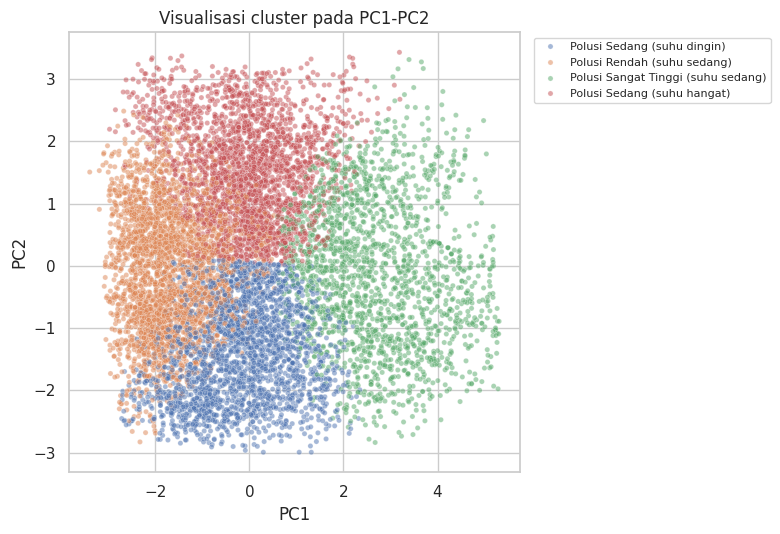

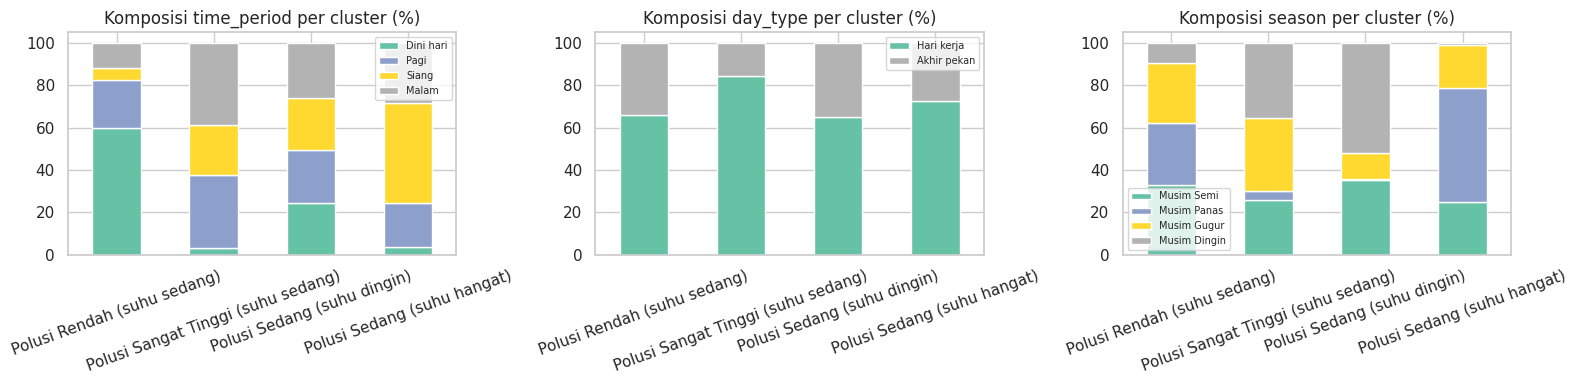

=== INSIGHT OTOMATIS PER CLUSTER ===

[Polusi Rendah (suhu sedang)] n = 2693 (28.8%)
  - CO rata-rata 1.00 mg/m3, NOx rata-rata 96 ppb, suhu rata-rata 17.7 C
  - Periode dominan : Dini hari (60%)
  - Jenis hari      : Hari kerja (66%)
  - Musim dominan   : Musim Semi (33%)

[Polusi Sedang (suhu dingin)] n = 2330 (24.9%)
  - CO rata-rata 1.67 mg/m3, NOx rata-rata 223 ppb, suhu rata-rata 10.1 C
  - Periode dominan : Malam (26%)
  - Jenis hari      : Hari kerja (65%)
  - Musim dominan   : Musim Dingin (52%)

[Polusi Sedang (suhu hangat)] n = 2466 (26.4%)
  - CO rata-rata 2.14 mg/m3, NOx rata-rata 169 ppb, suhu rata-rata 28.4 C
  - Periode dominan : Siang (47%)
  - Jenis hari      : Hari kerja (73%)
  - Musim dominan   : Musim Panas (54%)

[Polusi Sangat Tinggi (suhu sedang)] n = 1868 (20.0%)
  - CO rata-rata 4.11 mg/m3, NOx rata-rata 530 ppb, suhu rata-rata 16.1 C
  - Periode dominan : Malam (39%)
  - Jenis hari      : Hari kerja (85%)
  - Musim dominan   : Musim Dingin (36%)


In [28]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_km_z)
plot_df = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "Cluster": df_analytic["cluster_name"]})

plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", alpha=0.5, s=14)
plt.title("Visualisasi cluster pada PC1-PC2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
savefig("kmeans_cluster_pca")
plt.show()

# Komposisi waktu per cluster
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["time_period", "day_type", "season"]):
    comp = pd.crosstab(df_analytic["cluster_name"], df_analytic[col], normalize="index") * 100
    comp.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
    ax.set_title(f"Komposisi {col} per cluster (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=7)
plt.tight_layout()
savefig("cluster_komposisi_waktu")
plt.show()

print("=== INSIGHT OTOMATIS PER CLUSTER ===")
for cl in pol_idx.index:                       # urut dari polusi terendah
    sub = df_analytic[df_analytic["cluster"] == cl]
    dom_t = sub["time_period"].value_counts(normalize=True)
    dom_d = sub["day_type"].value_counts(normalize=True)
    dom_s = sub["season"].value_counts(normalize=True)
    print(f"\n[{cluster_names[cl]}] n = {len(sub)} ({len(sub)/len(df_analytic)*100:.1f}%)")
    print(f"  - CO rata-rata {sub['CO(GT)'].mean():.2f} mg/m3, NOx rata-rata {sub['NOx(GT)'].mean():.0f} ppb, "
          f"suhu rata-rata {sub['T'].mean():.1f} C")
    print(f"  - Periode dominan : {dom_t.index[0]} ({dom_t.iloc[0]*100:.0f}%)")
    print(f"  - Jenis hari      : {dom_d.index[0]} ({dom_d.iloc[0]*100:.0f}%)")
    print(f"  - Musim dominan   : {dom_s.index[0]} ({dom_s.iloc[0]*100:.0f}%)")

**Interpretasi E.2 dan insight praktis**

- **Pemilihan k.** Elbow menunjuk k = 4 (silhouette 0,245), sedangkan silhouette tertinggi ada pada k = 2 (0,303; hanya memisahkan kondisi bersih dan tercemar). Aturan pada Sel 26 menimbang keduanya secara eksplisit: selisih silhouette 0,058 (≤ 0,10) sehingga k = 4 dipilih. Nilai silhouette final 0,245 (di bawah 0,5) berarti cluster saling tumpang-tindih sebagian, jadi segmentasi ini dibaca sebagai **regime kondisi udara**, bukan kelompok yang terpisah tegas.
- **Makna cluster.** Cluster Polusi Sangat Tinggi (20,0% jam) memiliki rata-rata CO 4,11 mg/m3, benzena 20,17, NOx 530 ppb, dan NO2 162 ug/m3, jauh di atas cluster lain; cluster Polusi Rendah (28,8%) mencerminkan kondisi bersih (CO 1,00; NOx 96). Variabel cuaca (suhu) menambahkan pembeda musiman pada nama cluster.
- **Insight bisnis/praktis.** (1) Cluster polusi sangat tinggi terkonsentrasi pada malam hari (39%) dan hari kerja (85%), sehingga pembatasan lalu lintas, rekayasa lalu lintas, atau peringatan dini paling efektif diarahkan ke jam-jam tersebut. (2) Pemantauan dapat diprioritaskan pada kondisi cuaca yang berkaitan dengan cluster polusi tinggi. (3) Label cluster dapat dipakai sebagai fitur ringkas (indikator regime) untuk model prediksi kualitas udara.

##  Menyimpan dataset bersih dan ringkasan akhir
Menyimpan dataset hasil analisis dan membuat ringkasan otomatis untuk laporan.

In [29]:
df_analytic.to_csv(f"{OUT}/AirQuality_clean.csv", index=False)
print("Dataset bersih disimpan:", f"{OUT}/AirQuality_clean.csv")
print("Dimensi akhir:", df_analytic.shape)

summary_lines = [
    f"Tanggal akses/eksekusi        : {ACCESS_DATE}",
    f"Dimensi data mentah           : {df_raw.shape}",
    f"Kode -200 diubah menjadi NaN  : {int(sentinel_count.sum())}",
    f"Duplikat (penuh / datetime)   : {dup_full} / {dup_dt}",
    f"Kolom missing > 40% dibuang   : {high_missing_cols}",
    f"Missing setelah penanganan    : {int(df_analytic[analytic_meas].isna().sum().sum())}",
    f"Variabel outlier dianalisis   : {outlier_vars}",
    f"Komponen PCA untuk >= 80%     : {n_components_80}",
    f"k final K-Means               : {best_k} (silhouette {sil_final:.3f})",
    f"Nama cluster                  : {list(cluster_names.values())}",
]
with open(f"{OUT}/ringkasan_otomatis.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))
print("\n" + "\n".join(summary_lines))
print("\nSeluruh tabel dan grafik tersimpan di folder:", OUT)

Dataset bersih disimpan: outputs/AirQuality_clean.csv
Dimensi akhir: (9357, 40)

Tanggal akses/eksekusi        : 2026-10-17
Dimensi data mentah           : (9357, 15)
Kode -200 diubah menjadi NaN  : 16701
Duplikat (penuh / datetime)   : 0 / 0
Kolom missing > 40% dibuang   : ['NMHC(GT)']
Missing setelah penanganan    : 0
Variabel outlier dianalisis   : ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH']
Komponen PCA untuk >= 80%     : 3
k final K-Means               : 4 (silhouette 0.245)
Nama cluster                  : ['Polusi Rendah (suhu sedang)', 'Polusi Sedang (suhu dingin)', 'Polusi Sedang (suhu hangat)', 'Polusi Sangat Tinggi (suhu sedang)']

Seluruh tabel dan grafik tersimpan di folder: outputs
